# IT135IU Group 3, Topic 8: D3 Analysis
**Decision question:** which film genres should the Content Marketing and Promotion Team promote to each gender x age-group segment, instead of promoting the same genres to everyone? **Data:** MovieLens 1M (GroupLens).

| No. | Role | Name | Student ID |
|-----|------|------|------------|
| 1 | Product owner | Truc Phuong | ITDSIU25031 |
| 2 | Data engineer | Le Quan | ITDSIU25033 |
| 3 | Data analyst A | Que | ITDSIU25036 |
| 4 | Data analyst B | Hoang Quan | ITDSIU25035 |
| 5 | Visualisation lead | Tuyen | ITDSIU23028 |
| 6 | Reproducibility lead | Trung | ITDSIU24054 |
| 7 | Ethics and privacy officer | Cuong | ITDSIU25008 |

## Source and terms of use
- **Dataset:** MovieLens 1M, [grouplens.org/datasets/movielens/1m/](https://grouplens.org/datasets/movielens/1m/) (file loaded in Step 1 from [files.grouplens.org/datasets/movielens/ml-1m.zip](https://files.grouplens.org/datasets/movielens/ml-1m.zip))
- **Publisher:** GroupLens Research, University of Minnesota
- **Date of retrieval:** 28/09/2026
- **Terms of use** (copied from the README in ml-1m.zip):
  Neither the University of Minnesota nor any of the researchers involved can guarantee the correctness of the data, its suitability for any particular purpose, or the validity of results based on the use of the data set. The data set may be used for any research purposes under the following conditions:
  - The user may not state or imply any endorsement from the University of Minnesota or the GroupLens Research Group.
  - The user must acknowledge the use of the data set in publications resulting from the use of the data set (see below for citation information).
  - The user may not redistribute the data without separate permission.
  - The user may not use this information for any commercial or revenue-bearing purposes without first obtaining permission from a faculty member of the GroupLens Research Project at the University of Minnesota.

**Citation:**
> F. Maxwell Harper and Joseph A. Konstan. 2015. The MovieLens Datasets: History and Context. *ACM Transactions on Interactive Intelligent Systems (TiiS)* 5, 4, Article 19 (December 2015), 19 pages. DOI: [http://dx.doi.org/10.1145/2827872](http://dx.doi.org/10.1145/2827872)

## Terms used in this notebook
- **segment**: one gender × age group, e.g. F 25-34 (2 × 7 = 14 segments).
- **cell**: one segment × genre pair, e.g. F 25-34 × Drama (14 × 18 = 252 cells). Code blocks are always referred to by their Step number, never as cells.
- **tier**: reliability label of a cell, based on its number of distinct users.
- **satisfaction rate**: share of a cell's ratings that are 4 or 5 stars.

## Terms used in this notebook
- **Segment:** one gender × age group (2 × 7 = 14 segments).
- **Cell:** one segment × genre pair (14 × 18 = 252 cells).
- **Step:** one code block of this notebook. Steps 1 to 9 are carried over unchanged from D2. D3 Steps are named after the analysis steps: Step B1 to Step B9 (analysis), Step B10.1 to Step B10.4 (charts), Step Q1 and Step Q2 (descriptive and summary tables).
- **Satisfaction rate:** share of a cell's ratings that are 4 or 5 stars (rating-level).
- **Tier:** a cell is *reliable* with at least 100 distinct users, *indicative* otherwise. Tiers are computed once on the full data (Step 7) and kept on both halves.
- **Discovery half / validation half:** users of each segment are split at random into two halves (Step B1). Genres are chosen on the discovery half and tested on the validation half.

### Step 1: Load the Three Raw Tables
Load the raw files (`ratings.dat`, `users.dat`, and `movies.dat`) from the MovieLens zip file. The file is downloaded from GroupLens; if the download fails three times, a local copy in `data/ml-1m.zip` is used (cleaning log C19).

In [1]:
import io
import ssl
import time
import urllib.request
import zipfile
from pathlib import Path
from typing import Any
import numpy as np
import pandas as pd
import re

SEED = 42
np.random.seed(SEED)

URL = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"
LOCAL_ZIP = Path("data/ml-1m.zip")  # used only if the download fails; never committed
READ: dict[str, Any] = {
    "sep": "::",
    "engine": "python",
    "encoding": "latin-1",
    "header": None,
}

AGE_LABEL = {
    1: "Under 18",
    18: "18-24",
    25: "25-34",
    35: "35-44",
    45: "45-49",
    50: "50-55",
    56: "56+",
}

def load(archive: zipfile.ZipFile, name: str, cols: list[str]) -> pd.DataFrame:
    """Read one "::" separated member straight out of the archive."""
    data = io.BytesIO(archive.read(f"ml-1m/{name}"))
    return pd.read_csv(data, names=cols, **READ)


def fetch_zip(url: str, local: Path, tries: int = 3, wait: int = 5) -> zipfile.ZipFile:
    """Download the archive with certifi certificates; fall back to a local copy.

    Certificate verification is never turned off. If every attempt fails and
    there is no local copy, stop with instructions for a manual download.
    """
    try:
        import certifi
        context = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        context = ssl.create_default_context()

    last_error = None
    for attempt in range(1, tries + 1):
        try:
            with urllib.request.urlopen(url, context=context, timeout=60) as resp:
                data = resp.read()
            print(f"source : {url} (download, attempt {attempt})")
            return zipfile.ZipFile(io.BytesIO(data))
        except Exception as err:  # network or certificate error
            last_error = err
            print(f"download attempt {attempt} failed: {type(err).__name__}: {err}")
            if attempt < tries:
                time.sleep(wait)

    if local.exists():
        print(f"source : local copy {local}")
        return zipfile.ZipFile(local)

    raise RuntimeError(
        f"Could not download {url} ({last_error}) and found no local copy at {local}. "
        "Download ml-1m.zip by hand from https://grouplens.org/datasets/movielens/1m/ "
        "and put it in a folder named data/ next to this notebook."
    )

print("STEP 1  load the three raw tables")
zf = fetch_zip(URL, LOCAL_ZIP)
print("members inside zip:")
for member in zf.namelist():
    print(f"  - {member}")

ratings = load(zf, "ratings.dat", ["user_id", "movie_id", "rating", "timestamp"])
users = load(zf, "users.dat", ["user_id", "gender", "age", "occupation", "zip"])
movies = load(zf, "movies.dat", ["movie_id", "title", "genres"])

STEP 1  load the three raw tables
source : https://files.grouplens.org/datasets/movielens/ml-1m.zip (download, attempt 1)
members inside zip:
  - ml-1m/
  - ml-1m/movies.dat
  - ml-1m/ratings.dat
  - ml-1m/README
  - ml-1m/users.dat


### Step 2: Missing Values, Keys, and Orphan Rows
Validate the integrity of our tables by checking for missing values, confirming primary keys are unique, and identifying any orphaned foreign keys.

In [2]:
print("STEP 2  missing values, keys and orphan rows")

for name, table in [
    ("ratings", ratings),
    ("users", users),
    ("movies", movies),
]:
    print(f"\n{name}: shape={table.shape}")
    print(table.isna().sum().to_string())

print("\nprimary key uniqueness")
print(f"  users.user_id   : {users['user_id'].is_unique}")
print(f"  movies.movie_id : {movies['movie_id'].is_unique}")

bad_user = ~ratings["user_id"].isin(users["user_id"])
bad_movie = ~ratings["movie_id"].isin(movies["movie_id"])

n_bad_user = bad_user.sum()
n_bad_movie = bad_movie.sum()
d_bad_user = ratings.loc[bad_user, "user_id"].nunique()
d_bad_movie = ratings.loc[bad_movie, "movie_id"].nunique()

print("\norphan foreign keys in ratings")
print(f"  rows, unknown user_id     : {n_bad_user:,}")
print(f"  rows, unknown movie_id    : {n_bad_movie:,}")
print(f"  distinct unknown user_id  : {d_bad_user}")
print(f"  distinct unknown movie_id : {d_bad_movie}")

STEP 2  missing values, keys and orphan rows

ratings: shape=(1000209, 4)
user_id      0
movie_id     0
rating       0
timestamp    0

users: shape=(6040, 5)
user_id       0
gender        0
age           0
occupation    0
zip           0

movies: shape=(3883, 3)
movie_id    0
title       0
genres      0

primary key uniqueness
  users.user_id   : True
  movies.movie_id : True

orphan foreign keys in ratings
  rows, unknown user_id     : 0
  rows, unknown movie_id    : 0
  distinct unknown user_id  : 0
  distinct unknown movie_id : 0


### Step 2b: Data Profile of the Three Raw Tables
Rows, columns, types, missing values, distinct values and ranges for each raw table (the profile table required by the brief).

In [3]:
print("STEP 2b  data profile of the raw tables")

def profile(table: pd.DataFrame, name: str) -> pd.DataFrame:
    """One row per column: dtype, missing, distinct values and numeric range."""
    rows = []
    for col in table.columns:
        s = table[col]
        numeric = pd.api.types.is_numeric_dtype(s)
        rows.append(
            {
                "column": col,
                "dtype": str(s.dtype),
                "missing": int(s.isna().sum()),
                "unique": int(s.nunique()),
                "min": s.min() if numeric else "-",
                "max": s.max() if numeric else "-",
            }
        )
    print(f"\n{name}: {table.shape[0]:,} rows x {table.shape[1]} columns")
    out = pd.DataFrame(rows)
    print(out.to_string(index=False))
    return out

for name, table in [("ratings", ratings), ("users", users), ("movies", movies)]:
    profile(table, name)

STEP 2b  data profile of the raw tables

ratings: 1,000,209 rows x 4 columns
   column dtype  missing  unique       min        max
  user_id int64        0    6040         1       6040
 movie_id int64        0    3706         1       3952
   rating int64        0       5         1          5
timestamp int64        0  458455 956703932 1046454590

users: 6,040 rows x 5 columns
    column  dtype  missing  unique min  max
   user_id  int64        0    6040   1 6040
    gender object        0       2   -    -
       age  int64        0       7   1   56
occupation  int64        0      21   0   20
       zip object        0    3439   -    -

movies: 3,883 rows x 3 columns
  column  dtype  missing  unique min  max
movie_id  int64        0    3883   1 3952
   title object        0    3883   -    -
  genres object        0     301   -    -


### Step 2c: Duplicate, Validity and Coverage Checks
Duplicate rating pairs, valid value ranges, rating period, and films that no one rated.

In [4]:
print("STEP 2c  duplicate, validity and coverage checks")

n_dup_pairs = ratings.duplicated(subset=["user_id", "movie_id"]).sum()
n_dup_rows = ratings.duplicated().sum()
print("duplicate rows in ratings")
print(f"  repeated (user_id, movie_id) pairs : {n_dup_pairs:,}")
print(f"  fully identical rows               : {n_dup_rows:,}")

print("\nvalid value ranges")
print(f"  rating values : {[int(x) for x in sorted(ratings['rating'].unique())]}")
print(f"  gender codes  : {sorted(users['gender'].unique())}")
stamps = pd.to_datetime(ratings["timestamp"], unit="s", utc=True)
print(f"  first rating  : {stamps.min()}")
print(f"  last rating   : {stamps.max()}")

rated_ids = set(ratings["movie_id"])
n_unrated = (~movies["movie_id"].isin(rated_ids)).sum()
print("\nfilm coverage")
print(f"  films in movies.dat      : {len(movies):,}")
print(f"  films with >= 1 rating   : {len(rated_ids):,}")
print(f"  films never rated        : {n_unrated:,}")
print(f"  highest movie_id         : {movies['movie_id'].max():,}")
print(f"  unused ids up to highest : {movies['movie_id'].max() - len(movies):,}")
print(f"  fewest ratings by one user : {ratings.groupby('user_id').size().min()}")

STEP 2c  duplicate, validity and coverage checks
duplicate rows in ratings
  repeated (user_id, movie_id) pairs : 0
  fully identical rows               : 0

valid value ranges
  rating values : [1, 2, 3, 4, 5]
  gender codes  : ['F', 'M']
  first rating  : 2000-04-25 23:05:32+00:00
  last rating   : 2003-02-28 17:49:50+00:00

film coverage
  films in movies.dat      : 3,883
  films with >= 1 rating   : 3,706
  films never rated        : 177
  highest movie_id         : 3,952
  unused ids up to highest : 69
  fewest ratings by one user : 20


### Step 2d: Additional Checks (Data Analyst A)
Three checks taken from the independent notebook of Data Analyst A (Que): row counts against the README, ratings dated before the film's release year, and ratings entered in the same second by the same user. Nothing is removed here; the results are recorded in the cleaning log (C17). Two notebooks built separately give the same row counts and checks.

In [5]:
print("STEP 2d (1)  row counts against the README")

readme = re.sub(r"\s+", " ", zf.read("ml-1m/README").decode("latin-1"))
ref_ratings = int(re.search(r"([\d,]+) anonymous ratings", readme).group(1).replace(",", ""))
ref_users = int(re.search(r"made by ([\d,]+) MovieLens users", readme).group(1).replace(",", ""))

print(f"  ratings : README {ref_ratings:,}, file {len(ratings):,}, match {ref_ratings == len(ratings)}")
print(f"  users   : README {ref_users:,}, file {len(users):,}, match {ref_users == len(users)}")

STEP 2d (1)  row counts against the README
  ratings : README 1,000,209, file 1,000,209, match True
  users   : README 6,040, file 6,040, match True


In [6]:
print("STEP 2d (2)  ratings dated before the film's release year")

release_year = (
    movies.set_index("movie_id")["title"]
    .str.extract(r"\((\d{4})\)\s*$", expand=False)
    .astype(int)
)
rated_year = pd.to_datetime(ratings["timestamp"], unit="s", utc=True).dt.year
before = rated_year < ratings["movie_id"].map(release_year)

print(f"  ratings checked           : {len(ratings):,}")
print(f"  rated before release year : {before.sum():,}")

STEP 2d (2)  ratings dated before the film's release year
  ratings checked           : 1,000,209
  rated before release year : 0


In [7]:
print("STEP 2d (3)  ratings entered in the same second by the same user")

per_second = ratings.groupby(["user_id", "timestamp"]).size()
in_burst = int(per_second[per_second > 1].sum())

print(f"  ratings checked                         : {len(ratings):,}")
print(f"  ratings sharing a second with another   : {in_burst:,} ({in_burst / len(ratings):.1%})")
print(f"  largest burst, one user in one second   : {per_second.max()} ratings")

STEP 2d (3)  ratings entered in the same second by the same user
  ratings checked                         : 1,000,209
  ratings sharing a second with another   : 774,028 (77.4%)
  largest burst, one user in one second   : 30 ratings


### Step 3: Merge Into One Working Table
Merge the `ratings`, `users`, and `movies` DataFrames using left joins.

In [8]:
print("STEP 3  merge into one working table")

df = ratings.merge(users, on="user_id", how="left", validate="m:1")
df = df.merge(movies, on="movie_id", how="left", validate="m:1")

assert len(df) == len(ratings), "left merge changed the row count"

print(f"shape     : {df.shape}")
print(f"columns   : {df.columns.tolist()}")
print(f"total NaN : {df.isna().sum().sum()}")

STEP 3  merge into one working table
shape     : (1000209, 10)
columns   : ['user_id', 'movie_id', 'rating', 'timestamp', 'gender', 'age', 'occupation', 'zip', 'title', 'genres']
total NaN : 0


### Step 3b: Drop Personal Columns
`zip` and `occupation` are dropped from the working table: zip code combined with gender and age band could narrow down an individual, and neither column is used in the analysis (as committed in D1).

In [9]:
print("STEP 3b  drop personal columns")

before = df.shape[1]
df = df.drop(columns=["zip", "occupation"])
print(f"columns before : {before}")
print(f"columns after  : {df.shape[1]}")
print(f"columns        : {df.columns.tolist()}")
assert len(df) == len(ratings), "dropping columns changed the row count"

STEP 3b  drop personal columns
columns before : 10
columns after  : 8
columns        : ['user_id', 'movie_id', 'rating', 'timestamp', 'gender', 'age', 'title', 'genres']


### Step 4: Derived Columns (Year and Age Group)
Extract the release year from movie titles and map numeric age codes to readable categories.

In [10]:
print("STEP 4  derived columns, year and age_group")

df["year"] = (
    df["title"].str.extract(r"\((\d{4})\)\s*$", expand=False).astype("Int64")
)

print(f"rows with NaN year : {df['year'].isna().sum()}")
print(f"year.min()         : {df['year'].min()}")
print(f"year.max()         : {df['year'].max()}")

codes = df["age"]
df["age_group"] = codes.map(AGE_LABEL)

assert df["age_group"].isna().sum() == 0, "unmapped age code found"

print(f"\nrows with NaN age_group : {df['age_group'].isna().sum()}")

age_order = [AGE_LABEL[code] for code in sorted(AGE_LABEL)]
print(df["age_group"].value_counts().reindex(age_order).to_string())

STEP 4  derived columns, year and age_group
rows with NaN year : 0
year.min()         : 1919
year.max()         : 2000

rows with NaN age_group : 0
age_group
Under 18     27211
18-24       183536
25-34       395556
35-44       199003
45-49        83633
50-55        72490
56+          38780


In [11]:
print("STEP 4b  release-year coverage")

years_rated = set(df["year"].dropna().astype(int))
years_all = set(
    movies["title"].str.extract(r"\((\d{4})\)\s*$", expand=False).dropna().astype(int)
)
span = range(min(years_all), max(years_all) + 1)
print(f"distinct years, rated films in df : {len(years_rated)}")
print(f"distinct years, all of movies.dat : {len(years_all)}")
print(f"years in the span with no film    : {[y for y in span if y not in years_all]}")

STEP 4b  release-year coverage
distinct years, rated films in df : 81
distinct years, all of movies.dat : 81
years in the span with no film    : [1924]


### Step 5: Genre Breakdown
Explode the concatenated genres so each row represents a single rating-genre pair.

In [12]:
print("STEP 5  genre breakdown")

genres = df.copy()
genres["genre_list"] = genres["genres"].str.split("|")
genres["n_genres"] = genres["genre_list"].str.len()

print("n_genres per rating row")
print(genres["n_genres"].describe().to_string())

exploded = genres.explode("genre_list").rename(columns={"genre_list": "genre"})

print(f"\nrows after explode : {len(exploded):,}")
print(f"ratio to ratings   : {len(exploded) / len(ratings):.4f}")
print(f"distinct genres    : {exploded['genre'].nunique()}")
print(exploded["genre"].value_counts().to_string())

STEP 5  genre breakdown
n_genres per rating row
count    1.000209e+06
mean     2.101376e+00
std      9.768456e-01
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      3.000000e+00
max      6.000000e+00

rows after explode : 2,101,815
ratio to ratings   : 2.1014
distinct genres    : 18
genre
Comedy         356580
Drama          354529
Action         257457
Thriller       189680
Sci-Fi         157294
Romance        147523
Adventure      133953
Crime           79541
Horror          76386
Children's      72186
War             68527
Animation       43293
Musical         41533
Mystery         40178
Fantasy         36301
Western         20683
Film-Noir       18261
Documentary      7910


In [13]:
print("STEP 5b  labels per film and genre combinations")

per_film_all = movies["genres"].str.count(r"\|") + 1
per_film_rated = per_film_all[movies["movie_id"].isin(rated_ids)]
print(f"distinct genre combinations         : {movies['genres'].nunique()}")
print(f"mean labels per rating row (df)     : {genres['n_genres'].mean():.4f}")
print(f"mean labels per film, all movies    : {per_film_all.mean():.4f}")
print(f"mean labels per film, rated movies  : {per_film_rated.mean():.4f}")

STEP 5b  labels per film and genre combinations
distinct genre combinations         : 301
mean labels per rating row (df)     : 2.1014
mean labels per film, all movies    : 1.6503
mean labels per film, rated movies  : 1.6708


### Step 6: Cell Sparsity
Count distinct users and ratings in each of the 252 cells (segment × genre) to see which cells have thin data support.

In [14]:
print("STEP 6  cell sparsity")

cells = (
    exploded.groupby(["gender", "age_group", "genre"], observed=True)
    .agg(n_ratings=("rating", "size"), n_users=("user_id", "nunique"))
    .reset_index()
    .sort_values("n_users")
)

cells["age_group"] = pd.Categorical(
    cells["age_group"], age_order, ordered=True
)

print(f"cells present    : {len(cells)}")
print(f"full grid 2x7x18 : {2 * 7 * 18}")
print("\nn_users per cell")
print(cells["n_users"].describe().round(1).to_string())

for limit in (30, 50, 100):
    thin = cells[cells["n_users"] < limit]
    share = len(thin) / len(cells)
    print(
        f"\nunder {limit} users: {len(thin)} of {len(cells)} cells ({share:.1%})"
    )
    rows = zip(
        thin["gender"],
        thin["age_group"],
        thin["genre"],
        thin["n_users"],
        thin["n_ratings"],
    )
    for gender, age, genre, n_users, n_ratings in rows:
        label = f"{gender} {age}"
        print(
            f"  {label:<12} {genre:<12} {n_users:>3} users, {n_ratings:>5} ratings"
        )

STEP 6  cell sparsity
cells present    : 252
full grid 2x7x18 : 252

n_users per cell
count     252.0
mean      372.6
std       354.7
min        11.0
25%       133.5
50%       270.5
75%       460.5
max      1538.0

under 30 users: 3 of 252 cells (1.2%)
  F Under 18   Documentary   11 users,    25 ratings
  F Under 18   Film-Noir     26 users,    80 ratings
  F 56+        Documentary   29 users,    72 ratings

under 50 users: 5 of 252 cells (2.0%)
  F Under 18   Documentary   11 users,    25 ratings
  F Under 18   Film-Noir     26 users,    80 ratings
  F 56+        Documentary   29 users,    72 ratings
  F Under 18   Western       35 users,    91 ratings
  M Under 18   Documentary   45 users,   105 ratings

under 100 users: 41 of 252 cells (16.3%)
  F Under 18   Documentary   11 users,    25 ratings
  F Under 18   Film-Noir     26 users,    80 ratings
  F 56+        Documentary   29 users,    72 ratings
  F Under 18   Western       35 users,    91 ratings
  M Under 18   Documentary   4

### Step 7: Freeze the Reliability Threshold into a Tier Column
A cell is **reliable** if it holds at least 100 distinct users, and **indicative** otherwise. The threshold was fixed in D1 (Section 5, Feasibility note) before any satisfaction rate was computed. Cell size is counted in distinct users, not ratings, because one person's ratings are not independent of each other. Indicative cells stay in the cell table and are reported as indicative only; they are never used to rank a segment's genres. D1 allowed such cells to be "pooled or reported as indicative only"; this notebook takes the second option and does not pool.

In [15]:
print("STEP 7  freeze the reliability threshold into a tier column")

MIN_USERS = 100  # fixed in D1, Section 5, before any satisfaction rate was computed

cells["tier"] = np.where(cells["n_users"] >= MIN_USERS, "reliable", "indicative")

tier_counts = cells["tier"].value_counts().reindex(["reliable", "indicative"])
assert tier_counts.sum() == len(cells) == 2 * 7 * 18, "tiers miss some cells"

print(f"threshold : {MIN_USERS} distinct users per cell")
print(tier_counts.to_string())
print(f"reliable share : {tier_counts['reliable'] / len(cells):.1%}")

print("\nreliable cells per segment (out of 18 genres)")
reliable_per_segment = (
    cells.groupby(["gender", "age_group"], observed=False)["tier"]
    .apply(lambda s: int((s == "reliable").sum()))
    .unstack("age_group")
)
print(reliable_per_segment.to_string())

STEP 7  freeze the reliability threshold into a tier column
threshold : 100 distinct users per cell
tier
reliable      211
indicative     41
reliable share : 83.7%

reliable cells per segment (out of 18 genres)
age_group  Under 18  18-24  25-34  35-44  45-49  50-55  56+
gender                                                     
F                 0     17     18     18     17     15    4
M                15     18     18     18     18     18   17


### Step 7b: Filter the Cells Used for Ranking
Data manipulation operation: filtering. Only reliable cells are kept in the table used to rank genres within a segment; indicative cells are set aside and reported separately.

In [16]:
print("STEP 7b  filter the cells used for ranking")

ranked = cells[cells["tier"] == "reliable"]
indicative = cells[cells["tier"] == "indicative"]
assert len(ranked) + len(indicative) == len(cells), "filter lost cells"

print(f"cells before filter            : {len(cells)}")
print(f"cells kept for ranking         : {len(ranked)}")
print(f"cells set aside as indicative  : {len(indicative)}")

STEP 7b  filter the cells used for ranking
cells before filter            : 252
cells kept for ranking         : 211
cells set aside as indicative  : 41


### Step 8: Satisfied Flag and Satisfaction Rate per Cell
Derived column `satisfied` (rating ≥ 4) and the satisfaction rate of each cell, as defined in D1 Section 2: the share of a cell's **ratings** that are 4 or 5 stars. No confidence interval is reported here: ratings from one user are not independent, so an interval that treats each rating as independent would be too narrow. User-level intervals are part of the D3 analysis. Rows below are sorted by segment and genre, not by rate; no genre is ranked in D2.

In [17]:
print("STEP 8  satisfied flag and satisfaction rate per cell")

exploded["satisfied"] = exploded["rating"] >= 4

rates = (
    exploded.groupby(["gender", "age_group", "genre"], observed=True)
    .agg(
        n_ratings=("rating", "size"),
        n_users=("user_id", "nunique"),
        n_satisfied=("satisfied", "sum"),
        sat_rate=("satisfied", "mean"),
    )
    .reset_index()
)

rates = rates.merge(
    cells[["gender", "age_group", "genre", "tier"]],
    on=["gender", "age_group", "genre"],
    how="left",
    validate="1:1",
)

assert len(rates) == len(cells), "cell count changed"
assert rates["sat_rate"].between(0, 1).all(), "sat_rate outside [0, 1]"
assert (rates["n_satisfied"] <= rates["n_ratings"]).all(), "more satisfied than ratings"

print(f"cells                                     : {len(rates)}")
print(f"share of ratings >= 4, all ratings, no explode : {(df['rating'] >= 4).mean():.4f}")
print("\nfirst rows of the cell table (sorted by segment and genre, not by rate)")
print(rates.sort_values(["gender", "age_group", "genre"]).head(5).to_string(index=False))

STEP 8  satisfied flag and satisfaction rate per cell
cells                                     : 252
share of ratings >= 4, all ratings, no explode : 0.5752

first rows of the cell table (sorted by segment and genre, not by rate)
gender age_group      genre  n_ratings  n_users  n_satisfied  sat_rate     tier
     F     18-24     Action       8593      296         4126  0.480158 reliable
     F     18-24  Adventure       5430      291         2611  0.480847 reliable
     F     18-24  Animation       3109      259         1806  0.580894 reliable
     F     18-24 Children's       5234      276         2575  0.491976 reliable
     F     18-24     Comedy      19136      298         9878  0.516200 reliable


### Step 9: Data Profile of the Working Table
Rows, columns, types, missing values, distinct values and ranges for the merged table `df` (after dropping personal columns and adding `year` and `age_group`).

In [18]:
print("STEP 9  data profile of the working table")

_ = profile(df, "df (working table)")

STEP 9  data profile of the working table

df (working table): 1,000,209 rows x 10 columns
   column  dtype  missing  unique       min        max
  user_id  int64        0    6040         1       6040
 movie_id  int64        0    3706         1       3952
   rating  int64        0       5         1          5
timestamp  int64        0  458455 956703932 1046454590
   gender object        0       2         -          -
      age  int64        0       7         1         56
    title object        0    3706         -          -
   genres object        0     301         -          -
     year  Int64        0      81      1919       2000
age_group object        0       7         -          -


## D3 analysis

### Step B1: Split Users into a Discovery Half and a Validation Half
Within each of the 14 segments, users are shuffled with seed 42 and split 50/50. The split is made on users, not on ratings, so all ratings of one person stay in the same half (ratings from one user are not independent). When a segment has an odd number of users, the extra user goes to the validation half. Genres are chosen on the discovery half (Steps B4 to B7) and tested on the validation half (Step B8), so the noise that helped a genre get selected is not counted again in the test. Only counts are printed here; no satisfaction rate is computed per half in this Step. Tiers stay as frozen in Step 7 on the full data.

In [19]:
print("STEP B1  split users into a discovery half and a validation half")

rng = np.random.default_rng(SEED)

seg_users = users[["user_id", "gender", "age"]].copy()
seg_users["age_group"] = seg_users["age"].map(AGE_LABEL)

half_of: dict[int, str] = {}
for gender in ["F", "M"]:              # fixed order, so the random draws are reproducible
    for age in age_order:
        in_seg = (seg_users["gender"] == gender) & (seg_users["age_group"] == age)
        ids = np.sort(seg_users.loc[in_seg, "user_id"].to_numpy())
        shuffled = rng.permutation(ids)
        n_discovery = len(ids) // 2    # odd count: the extra user goes to validation
        for uid in shuffled[:n_discovery]:
            half_of[int(uid)] = "discovery"
        for uid in shuffled[n_discovery:]:
            half_of[int(uid)] = "validation"

seg_users["half"] = seg_users["user_id"].map(half_of)
df["half"] = df["user_id"].map(half_of)
exploded["half"] = exploded["user_id"].map(half_of)

assert len(half_of) == len(users) == seg_users["user_id"].nunique(), "a user is missing or repeated"
assert seg_users["half"].notna().all(), "a user has no half"
assert df["half"].notna().all() and exploded["half"].notna().all(), "a rating has no half"
assert (df.groupby("user_id")["half"].nunique() == 1).all(), "a user appears in both halves"

users_per_half = (
    seg_users.groupby(["gender", "age_group", "half"]).size()
    .unstack("half")
    .reindex(pd.MultiIndex.from_product([["F", "M"], age_order], names=["gender", "age_group"]))
)
users_per_half["difference"] = users_per_half["validation"] - users_per_half["discovery"]
assert users_per_half["difference"].isin([0, 1]).all(), "halves differ by more than one user"

print("users per segment and half (difference = validation - discovery)")
print(users_per_half.to_string())
print(f"\nusers, discovery  : {(seg_users['half'] == 'discovery').sum():,}")
print(f"users, validation : {(seg_users['half'] == 'validation').sum():,}")
print(f"users, total      : {len(seg_users):,}")

ratings_per_half = df["half"].value_counts().reindex(["discovery", "validation"])
print("\nratings per half (working table df)")
for half, n in ratings_per_half.items():
    print(f"  {half:<10} : {n:,}")
print(f"  total      : {ratings_per_half.sum():,}")

STEP B1  split users into a discovery half and a validation half
users per segment and half (difference = validation - discovery)
half              discovery  validation  difference
gender age_group                                   
F      Under 18          39          39           0
       18-24            149         149           0
       25-34            279         279           0
       35-44            169         169           0
       45-49             94          95           1
       50-55             73          73           0
       56+               51          51           0
M      Under 18          72          72           0
       18-24            402         403           1
       25-34            769         769           0
       35-44            427         428           1
       45-49            180         181           1
       50-55            175         175           0
       56+              139         139           0

users, discovery  : 3,018
users, vali

### Step B2: Count n(u, g) and k(u, g) per User and Genre
For every user and every genre: n = number of ratings the user gave to films of that genre, k = number of those ratings with 4 or 5 stars. A user who rated no film of a genre gets n = k = 0. The table has one row per user and genre (6,040 x 18 rows) and keeps the half of each user.

In [20]:
print("STEP B2  user x genre counts n(u, g) and k(u, g)")

GENRES = sorted(exploded["genre"].unique())

per_user = exploded.groupby(["user_id", "genre"]).agg(
    n=("rating", "size"), k=("satisfied", "sum")
)
full_index = pd.MultiIndex.from_product(
    [seg_users["user_id"].sort_values(), GENRES], names=["user_id", "genre"]
)
user_genre = per_user.reindex(full_index, fill_value=0).reset_index()
user_genre["k"] = user_genre["k"].astype(int)
user_genre = user_genre.merge(
    seg_users[["user_id", "gender", "age_group", "half"]],
    on="user_id", how="left", validate="m:1",
)

assert len(user_genre) == len(users) * len(GENRES)
assert user_genre["n"].sum() == len(exploded)
assert user_genre["k"].sum() == exploded["satisfied"].sum()
assert (user_genre["k"] <= user_genre["n"]).all()

print(f"rows : {len(user_genre):,} ({len(users):,} users x {len(GENRES)} genres)")
print(f"sum n: {user_genre['n'].sum():,}   sum k: {user_genre['k'].sum():,}")
print(f"rows with n = 0 : {(user_genre['n'] == 0).sum():,}")
print(user_genre.head(3).to_string(index=False))

STEP B2  user x genre counts n(u, g) and k(u, g)
rows : 108,720 (6,040 users x 18 genres)
sum n: 2,101,815   sum k: 1,206,999
rows with n = 0 : 14,833
 user_id     genre  n  k gender age_group      half
       1    Action  5  4      F  Under 18 discovery
       1 Adventure  5  4      F  Under 18 discovery
       1 Animation 18 14      F  Under 18 discovery


### Step B3: Satisfaction Rate per Cell and Half
r(s, g) = sum of k / sum of n over the users of segment s, computed separately on the discovery half and the validation half. The table also carries the number of users, the tier from Step 7 (all data), and the reach of each cell. Column names follow D3_columns_HoangQuan_v2, Table 1.

In [21]:
print("STEP B3  satisfaction rate per cell and half")

rate_table = (
    user_genre.groupby(["gender", "age_group", "genre", "half"])
    .agg(
        n_ratings=("n", "sum"),
        n_satisfied=("k", "sum"),
        n_users=("n", lambda s: int((s > 0).sum())),
    )
    .reset_index()
)
rate_table["sat_rate"] = rate_table["n_satisfied"] / rate_table["n_ratings"]

tier_all = (
    cells[["gender", "age_group", "genre", "n_users", "tier"]]
    .rename(columns={"n_users": "n_users_all"})
    .astype({"age_group": str})
)
rate_table = rate_table.merge(
    tier_all, on=["gender", "age_group", "genre"], how="left", validate="m:1"
)

seg_size = (
    seg_users.groupby(["gender", "age_group", "half"]).size()
    .rename("segment_users").reset_index()
)
rate_table = rate_table.merge(
    seg_size, on=["gender", "age_group", "half"], how="left", validate="m:1"
)
rate_table["reach"] = rate_table["n_users"] / rate_table["segment_users"]

rate_table = rate_table[[
    "gender", "age_group", "genre", "half", "n_ratings", "n_users",
    "n_satisfied", "sat_rate", "n_users_all", "tier", "segment_users", "reach",
]]

assert len(rate_table) == 2 * 7 * 18 * 2
assert rate_table["sat_rate"].between(0, 1).all()
assert rate_table["tier"].notna().all() and rate_table["segment_users"].notna().all()

print(f"rows: {len(rate_table)}")
print(rate_table.dtypes.to_string())
check = (rate_table["gender"] == "F") & (rate_table["age_group"] == "18-24") & (rate_table["genre"] == "Action")
print(rate_table[check].to_string(index=False))

STEP B3  satisfaction rate per cell and half
rows: 504
gender            object
age_group         object
genre             object
half              object
n_ratings          int64
n_users            int64
n_satisfied        int64
sat_rate         float64
n_users_all        int64
tier              object
segment_users      int64
reach            float64
gender age_group  genre       half  n_ratings  n_users  n_satisfied  sat_rate  n_users_all     tier  segment_users    reach
     F     18-24 Action  discovery       4196      149         2128  0.507150          296 reliable            149 1.000000
     F     18-24 Action validation       4397      147         1998  0.454401          296 reliable            149 0.986577


### Step B4: Lower Confidence Bound (LCB) of Each Cell, Discovery Half
For each of the 14 segments, the users of the discovery half are resampled with replacement 1,000 times (whole users, not single ratings). In every round the rate of each genre is recomputed as sum of k / sum of n over the resampled users. LCB(s, g) is the 2.5% quantile of the 1,000 rates. The random generator is created at the start of this Step with seed 42.

In [22]:
print("STEP B4  LCB of each cell, discovery half")

N_BOOT = 1000
rng = np.random.default_rng(SEED)

disc = user_genre[user_genre["half"] == "discovery"]
parts = []
for gender in ["F", "M"]:            # fixed order, so the random draws are reproducible
    for age in age_order:
        seg = disc[(disc["gender"] == gender) & (disc["age_group"] == age)]
        n_mat = seg.pivot(index="user_id", columns="genre", values="n")[GENRES].to_numpy()
        k_mat = seg.pivot(index="user_id", columns="genre", values="k")[GENRES].to_numpy()
        n_users_seg = len(n_mat)
        pick = rng.integers(0, n_users_seg, size=(N_BOOT, n_users_seg))
        n_sum = n_mat[pick].sum(axis=1)
        k_sum = k_mat[pick].sum(axis=1)
        with np.errstate(divide="ignore", invalid="ignore"):
            boot_rates = k_sum / n_sum
        parts.append(pd.DataFrame({
            "gender": gender, "age_group": age, "genre": GENRES,
            "lcb": np.nanquantile(boot_rates, 0.025, axis=0),
        }))

lcb_table = pd.concat(parts, ignore_index=True)
disc_rates = rate_table[rate_table["half"] == "discovery"][
    ["gender", "age_group", "genre", "tier", "n_users", "sat_rate"]
]
lcb_table = disc_rates.merge(
    lcb_table, on=["gender", "age_group", "genre"], how="left", validate="1:1"
)

assert len(lcb_table) == 2 * 7 * 18
assert lcb_table["lcb"].notna().all()
assert (lcb_table["lcb"] <= lcb_table["sat_rate"]).all()

print(f"cells: {len(lcb_table)}; bootstrap rounds: {N_BOOT}")
f1824 = (lcb_table["gender"] == "F") & (lcb_table["age_group"] == "18-24")
print(lcb_table[f1824].sort_values("lcb", ascending=False).head(4).to_string(index=False))

STEP B4  LCB of each cell, discovery half
cells: 252; bootstrap rounds: 1000
gender age_group       genre       tier  n_users  sat_rate      lcb
     F     18-24 Documentary indicative       47  0.770492 0.679218
     F     18-24   Film-Noir   reliable       86  0.704981 0.624986
     F     18-24         War   reliable      142  0.664103 0.619972
     F     18-24     Musical   reliable      124  0.652962 0.600511


### Step B5: Rank Cells by LCB and Choose T(s)
Within each segment, only reliable cells are ranked by LCB (highest first). Ties are broken by the number of users in the cell (more first), then by genre name. T(s) is the set of the three reliable cells with the highest LCB. Indicative cells get no rank and are never in T(s). Column names follow D3_columns_HoangQuan_v2, Table 2.

In [23]:
print("STEP B5  rank cells by LCB and choose T(s)")

lcb_table["age_order"] = lcb_table["age_group"].map({a: i for i, a in enumerate(age_order)})
reliable = lcb_table[lcb_table["tier"] == "reliable"].sort_values(
    ["gender", "age_order", "lcb", "n_users", "genre"],
    ascending=[True, True, False, False, True],
)
reliable["rank_lcb"] = reliable.groupby(["gender", "age_group"]).cumcount() + 1

lcb_table = lcb_table.merge(
    reliable[["gender", "age_group", "genre", "rank_lcb"]],
    on=["gender", "age_group", "genre"], how="left", validate="1:1",
)
lcb_table["rank_lcb"] = lcb_table["rank_lcb"].astype("Int64")
lcb_table["in_top3"] = lcb_table["rank_lcb"].le(3).fillna(False).astype(bool)
lcb_table = lcb_table.sort_values(["gender", "age_order", "genre"]).reset_index(drop=True)
lcb_table = lcb_table[["gender", "age_group", "genre", "tier", "sat_rate", "lcb", "rank_lcb", "in_top3"]]

assert len(lcb_table) == 252
assert lcb_table.loc[lcb_table["tier"] == "indicative", "rank_lcb"].isna().all()
assert lcb_table[lcb_table["in_top3"]].groupby(["gender", "age_group"]).size().max() == 3

t_s = (
    lcb_table[lcb_table["in_top3"]]
    .sort_values(["gender", "age_group", "rank_lcb"])
    .groupby(["gender", "age_group"])["genre"].apply(lambda s: "; ".join(s))
)
print(f"segments with a T(s): {len(t_s)} of 14")
print(t_s.to_string())
print(lcb_table.dtypes.to_string())

STEP B5  rank cells by LCB and choose T(s)
segments with a T(s): 13 of 14
gender  age_group
F       18-24            Film-Noir; War; Musical
        25-34        Film-Noir; Documentary; War
        35-44            Film-Noir; War; Musical
        45-49                War; Musical; Drama
        50-55                War; Drama; Romance
        56+             Drama; Romance; Thriller
M       18-24        Film-Noir; War; Documentary
        25-34        Film-Noir; Documentary; War
        35-44        Film-Noir; Documentary; War
        45-49              Film-Noir; War; Crime
        50-55            Film-Noir; War; Mystery
        56+              Film-Noir; War; Musical
        Under 18               War; Drama; Crime
gender        object
age_group     object
genre         object
tier          object
sat_rate     float64
lcb          float64
rank_lcb       Int64
in_top3         bool


### Step B6: Baseline B (Weighted Score of the Common Campaign), Discovery Half
B is the set of three genres promoted to everyone. It uses the 12 reference segments (segments with at least 15 reliable cells) and the 15 candidate genres (the 18 genres without Documentary, Film-Noir and Western). Each segment has a weight w(s) = N(s) / sum of N over the 12 segments, where N(s) is the number of users of the segment in the full users table. The score of a genre is S(g) = sum of w(s) x r(s, g), with r(s, g) the discovery-half rate. LCB of S(g) is the 2.5% quantile of 1,000 bootstrap rounds (users resampled within each segment, weights kept fixed). B = the three genres with the highest LCB; ties are broken by the number of users, then by genre name. Column names follow D3_columns_HoangQuan_v2, Table 3.


In [24]:
print("STEP B6  baseline B (weighted, discovery half)")

EXCLUDED = ["Documentary", "Film-Noir", "Western"]
CANDIDATES = [g for g in GENRES if g not in EXCLUDED]

reliable_count = (
    cells[cells["tier"] == "reliable"].groupby(["gender", "age_group"], observed=True).size()
)
ref_segments = [
    (g, a) for g in ["F", "M"] for a in age_order if reliable_count.get((g, a), 0) >= 15
]

seg_n = seg_users.groupby(["gender", "age_group"]).size()
weights = {s: seg_n[s] / sum(seg_n[t] for t in ref_segments) for s in ref_segments}

tier_lookup = tier_all.set_index(["gender", "age_group", "genre"])["tier"]
assert all(
    tier_lookup[(g, a, c)] == "reliable" for (g, a) in ref_segments for c in CANDIDATES
)

rng = np.random.default_rng(SEED)
disc = user_genre[user_genre["half"] == "discovery"]
s_point = np.zeros(len(CANDIDATES))
s_boot = np.zeros((N_BOOT, len(CANDIDATES)))
n_users_total = np.zeros(len(CANDIDATES))
for (gender, age) in ref_segments:
    seg = disc[(disc["gender"] == gender) & (disc["age_group"] == age)]
    n_mat = seg.pivot(index="user_id", columns="genre", values="n")[CANDIDATES].to_numpy()
    k_mat = seg.pivot(index="user_id", columns="genre", values="k")[CANDIDATES].to_numpy()
    w = weights[(gender, age)]
    s_point += w * k_mat.sum(axis=0) / n_mat.sum(axis=0)
    pick = rng.integers(0, len(n_mat), size=(N_BOOT, len(n_mat)))
    s_boot += w * k_mat[pick].sum(axis=1) / n_mat[pick].sum(axis=1)
    n_users_total += (n_mat > 0).sum(axis=0)

baseline_table = pd.DataFrame({
    "genre": CANDIDATES,
    "s_g": s_point,
    "lcb": np.quantile(s_boot, 0.025, axis=0),
    "n_users_total": n_users_total,
})
baseline_table = baseline_table.sort_values(
    ["lcb", "n_users_total", "genre"], ascending=[False, False, True]
).reset_index(drop=True)
baseline_table["rank_lcb"] = baseline_table.index + 1
baseline_table["in_baseline"] = baseline_table["rank_lcb"] <= 3
baseline_table = baseline_table[["genre", "s_g", "lcb", "rank_lcb", "in_baseline"]]

assert len(ref_segments) == 12 and len(baseline_table) == 15
assert abs(sum(weights.values()) - 1) < 1e-12
assert baseline_table["in_baseline"].sum() == 3
B = baseline_table.loc[baseline_table["in_baseline"], "genre"].tolist()
print(f"reference segments: {len(ref_segments)}; candidate genres: {len(CANDIDATES)}")
print(baseline_table.to_string(index=False))
print("B =", "; ".join(B))

STEP B6  baseline B (weighted, discovery half)
reference segments: 12; candidate genres: 15
     genre      s_g      lcb  rank_lcb  in_baseline
       War 0.690715 0.680999         1         True
     Drama 0.640402 0.629756         2         True
     Crime 0.619416 0.608235         3         True
 Animation 0.619236 0.606261         4        False
   Musical 0.600899 0.586528         5        False
   Mystery 0.593810 0.579815         6        False
   Romance 0.574833 0.563578         7        False
  Thriller 0.564373 0.553793         8        False
    Comedy 0.553472 0.543199         9        False
    Action 0.536783 0.526770        10        False
 Adventure 0.531281 0.520986        11        False
    Sci-Fi 0.524124 0.514298        12        False
Children's 0.522101 0.508674        13        False
   Fantasy 0.515268 0.503547        14        False
    Horror 0.438634 0.425255        15        False
B = War; Drama; Crime


### Step B7: Classify the 14 Segments and Count m
Before any test, each segment gets one of three labels, using only the tier and the discovery half (section 3.8 of the shared card): insufficient_evidence (the segment has no reliable cell, or a genre of B is indicative in the segment), same_as_baseline (T(s) equals B exactly, so there is nothing to test), or tested (all others). m is the number of segments to be tested. Step B9 turns "tested" into passed or not_passed after the Holm correction.

In [25]:
print("STEP B7  classify segments and count m")

rows = []
for gender in ["F", "M"]:
    for age in age_order:
        seg_cells = lcb_table[(lcb_table["gender"] == gender) & (lcb_table["age_group"] == age)]
        t_list = seg_cells[seg_cells["in_top3"]].sort_values("rank_lcb")["genre"].tolist()
        indicative_b = [g for g in B if tier_lookup[(gender, age, g)] == "indicative"]
        if len(t_list) == 0:
            category, reason = "insufficient_evidence", "no reliable cell in the segment"
        elif indicative_b:
            category = "insufficient_evidence"
            reason = "genre of B is indicative in this segment: " + "; ".join(indicative_b)
        elif set(t_list) == set(B):
            category, reason = "same_as_baseline", "T(s) equals B, no test"
        else:
            category, reason = "tested", ""
        rows.append({
            "segment": f"{gender} {age}", "gender": gender, "age_group": age,
            "category": category, "reason": reason, "t_s": "; ".join(t_list),
        })

segment_status = pd.DataFrame(rows)
m = int((segment_status["category"] == "tested").sum())

assert len(segment_status) == 14
assert segment_status["category"].isin(["insufficient_evidence", "same_as_baseline", "tested"]).all()

print(segment_status[["segment", "category", "reason", "t_s"]].to_string(index=False))
print(f"\nm (segments to test) : {m}")
print(segment_status["category"].value_counts().to_string())

STEP B7  classify segments and count m
   segment              category                                               reason                         t_s
F Under 18 insufficient_evidence                      no reliable cell in the segment                            
   F 18-24                tested                                                          Film-Noir; War; Musical
   F 25-34                tested                                                      Film-Noir; Documentary; War
   F 35-44                tested                                                          Film-Noir; War; Musical
   F 45-49                tested                                                              War; Musical; Drama
   F 50-55                tested                                                              War; Drama; Romance
     F 56+ insufficient_evidence genre of B is indicative in this segment: War; Crime    Drama; Romance; Thriller
M Under 18      same_as_baseline                 

### Step B8: D(s), Confidence Interval and Raw p-value, Validation Half
For each tested segment, on the validation half: mean r over the three genres of T(s) minus mean r over the three genres of B, where r is the segment's satisfaction rate of the genre (sum of k / sum of n). D(s) is the difference. The users of the segment are resampled with replacement 10,000 times; the 95% interval is [Q0.025, Q0.975] of the resampled D, without correction for several tests. The two-sided p-value is p = 2 x min(share of D* <= 0, share of D* >= 0), capped at 1 (null hypothesis: D(s) = 0). The random generator is created at the start of this Step with seed 42.

In [26]:
print("STEP B8  D(s), confidence interval and raw p-value, validation half")

N_BOOT_TEST = 10_000
CHUNK = 1_000
rng = np.random.default_rng(SEED)

valid = user_genre[user_genre["half"] == "validation"]
test_rows = []
for _, seg_row in segment_status[segment_status["category"] == "tested"].iterrows():
    gender, age = seg_row["gender"], seg_row["age_group"]
    t_genres = seg_row["t_s"].split("; ")
    seg = valid[(valid["gender"] == gender) & (valid["age_group"] == age)]
    n_mat = seg.pivot(index="user_id", columns="genre", values="n")[GENRES].to_numpy()
    k_mat = seg.pivot(index="user_id", columns="genre", values="k")[GENRES].to_numpy()
    t_idx = [GENRES.index(g) for g in t_genres]
    b_idx = [GENRES.index(g) for g in B]

    def d_value(n_sum, k_sum):
        rate = k_sum / n_sum
        return rate[..., t_idx].mean(axis=-1) - rate[..., b_idx].mean(axis=-1)

    rate_all = k_mat.sum(axis=0) / n_mat.sum(axis=0)
    mean_r_ts = rate_all[t_idx].mean()
    mean_r_b = rate_all[b_idx].mean()
    d = mean_r_ts - mean_r_b

    boot_d = []
    for _ in range(N_BOOT_TEST // CHUNK):
        pick = rng.integers(0, len(n_mat), size=(CHUNK, len(n_mat)))
        boot_d.append(d_value(n_mat[pick].sum(axis=1), k_mat[pick].sum(axis=1)))
    boot_d = np.concatenate(boot_d)

    p_raw = min(1.0, 2 * min((boot_d <= 0).mean(), (boot_d >= 0).mean()))
    test_rows.append({
        "segment": seg_row["segment"], "mean_r_ts": mean_r_ts, "mean_r_b": mean_r_b, "d": d,
        "ci_low": np.quantile(boot_d, 0.025), "ci_high": np.quantile(boot_d, 0.975), "p_raw": p_raw,
    })

test_table = pd.DataFrame(test_rows)
assert len(test_table) == m
assert test_table["p_raw"].between(0, 1).all()
assert (test_table["ci_low"] <= test_table["ci_high"]).all()
print(f"segments tested: {len(test_table)}; bootstrap rounds per segment: {N_BOOT_TEST:,}")
print(test_table.round(4).to_string(index=False))

STEP B8  D(s), confidence interval and raw p-value, validation half
segments tested: 11; bootstrap rounds per segment: 10,000
segment  mean_r_ts  mean_r_b       d  ci_low  ci_high  p_raw
F 18-24     0.6000    0.5662  0.0338  0.0045   0.0619 0.0252
F 25-34     0.7190    0.6414  0.0776  0.0427   0.1069 0.0000
F 35-44     0.6872    0.6491  0.0381  0.0141   0.0616 0.0024
F 45-49     0.6344    0.6387 -0.0044 -0.0390   0.0280 0.8616
F 50-55     0.6710    0.6950 -0.0239 -0.0468   0.0030 0.0818
M 18-24     0.7322    0.6620  0.0702  0.0461   0.0917 0.0000
M 25-34     0.7283    0.6439  0.0844  0.0708   0.0974 0.0000
M 35-44     0.7392    0.6630  0.0762  0.0572   0.0942 0.0000
M 45-49     0.7244    0.6826  0.0418  0.0302   0.0528 0.0000
M 50-55     0.7289    0.6729  0.0560  0.0380   0.0723 0.0000
  M 56+     0.7372    0.7166  0.0206 -0.0043   0.0436 0.1004


### Step B9: Holm Correction and Final Results Table
The raw p-values of the m tested segments are sorted from smallest to largest. The j-th p-value passes if it is at most 0.05 / (m - j + 1) and every earlier p-value passed (the procedure stops at the first failure). p_holm is the adjusted p-value. A segment is "passed" only if it passes Holm and D(s) > 0; otherwise a tested segment is "not_passed". The adjusted p-values and decisions are checked against statsmodels.stats.multitest.multipletests(method="holm"). The 14-row results table follows D3_columns_HoangQuan_v2, Table 4.

In [27]:
print("STEP B9  Holm correction and final results table")

ALPHA = 0.05
order = test_table.sort_values("p_raw", kind="stable").reset_index(drop=True)
holm_pass_flags, p_holm_values = [], []
running_max, still_passing = 0.0, True
for j, p in enumerate(order["p_raw"], start=1):
    threshold = ALPHA / (m - j + 1)
    still_passing = still_passing and (p <= threshold)
    running_max = max(running_max, min(1.0, (m - j + 1) * p))
    holm_pass_flags.append(still_passing)
    p_holm_values.append(running_max)
order["p_holm"] = p_holm_values
order["holm_pass"] = holm_pass_flags

from statsmodels.stats.multitest import multipletests
reject, p_adj, _, _ = multipletests(order["p_raw"], alpha=ALPHA, method="holm")
assert np.allclose(order["p_holm"], p_adj), "Holm p-values differ from statsmodels"
assert (order["holm_pass"].to_numpy() == reject).all(), "Holm decisions differ from statsmodels"

order["passed"] = order["holm_pass"] & (order["d"] > 0)
results = segment_status.merge(
    order[["segment", "mean_r_ts", "mean_r_b", "d", "ci_low", "ci_high", "p_raw", "p_holm", "passed"]],
    on="segment", how="left", validate="1:1",
)
is_tested = results["category"] == "tested"
results.loc[is_tested, "category"] = np.where(
    results.loc[is_tested, "passed"].astype(bool), "passed", "not_passed"
)
results["m"] = m
results["conclusion"] = np.where(results["category"] == "passed", "own_campaign", "common_campaign")
results = results[[
    "segment", "gender", "age_group", "category", "reason", "t_s",
    "mean_r_ts", "mean_r_b", "d", "ci_low", "ci_high",
    "p_raw", "p_holm", "m", "conclusion",
]]

assert len(results) == 14
assert results["category"].isin(["insufficient_evidence", "same_as_baseline", "passed", "not_passed"]).all()
assert m == results["category"].isin(["passed", "not_passed"]).sum()

print(results[["segment", "category", "d", "p_raw", "p_holm", "conclusion"]].round(4).to_string(index=False))
print(f"\nm = {m}")
print(results["category"].value_counts().to_string())
print(results.dtypes.to_string())

STEP B9  Holm correction and final results table
   segment              category       d  p_raw  p_holm      conclusion
F Under 18 insufficient_evidence     NaN    NaN     NaN common_campaign
   F 18-24            not_passed  0.0338 0.0252  0.1008 common_campaign
   F 25-34                passed  0.0776 0.0000  0.0000    own_campaign
   F 35-44                passed  0.0381 0.0024  0.0120    own_campaign
   F 45-49            not_passed -0.0044 0.8616  0.8616 common_campaign
   F 50-55            not_passed -0.0239 0.0818  0.2454 common_campaign
     F 56+ insufficient_evidence     NaN    NaN     NaN common_campaign
M Under 18      same_as_baseline     NaN    NaN     NaN common_campaign
   M 18-24                passed  0.0702 0.0000  0.0000    own_campaign
   M 25-34                passed  0.0844 0.0000  0.0000    own_campaign
   M 35-44                passed  0.0762 0.0000  0.0000    own_campaign
   M 45-49                passed  0.0418 0.0000  0.0000    own_campaign
   M 50-55     

### Interpretation and limits of the test (Steps B6 to B9)

*Written by Data analyst B; every number below is printed by Step B6 or Step B9.*

**What the results show.** The common campaign B, chosen on the discovery half from the 15 candidate genres, is War, Drama and Crime (Step B6). Of the 14 segments, 2 have insufficient evidence (females under 18 have no reliable cell; in females 56+ two genres of B, War and Crime, are indicative), 1 has T(s) identical to B (males under 18), and m = 11 are tested on the validation half. Seven segments pass and four do not (Step B9).

In the 7 segments that passed (females 25-34 and 35-44; males 18-24, 25-34, 35-44, 45-49 and 50-55), the genres of T(s), chosen on the discovery half, have a higher satisfaction rate than the genres of B among the validation-half users of the same segment, by about 4 to 8 percentage points, and this holds after the Holm correction. In the other segments the data do not support a better own list: for females 18-24 the interval excludes 0 but the Holm-adjusted p-value (0.1008) does not pass, for males 56+ the interval includes 0, and for females 45-49 and 50-55 D(s) is not positive. A p-value printed as 0.0000 means that none of the 10,000 resampled values fell on the other side of 0; it is an approximation and should be read as "below 1 in 10,000".

**What the results do not establish.**
- D(s) is a difference between satisfaction rates of people who rated films; it does not measure the effect of promoting a genre, because the data contain no promotions and no information about who saw what.
- The association between gender, age group and rating is observational and does not show that either causes taste.
- Some genres that appear in many T(s) lists, such as Film-Noir and Documentary, were rated by fewer users than the genres of B and cannot be part of B at all because they are not reliable in every reference segment; these raters may be self-selected enthusiasts, so part of D(s) may reflect who chooses to rate such films, which this analysis cannot separate.
- The choice of B is close: Crime (rank 3) and Animation (rank 4) differ by about 0.002 in LCB (Step B6), and a different B would change m, since males under 18 would then no longer have T(s) equal to B.
- All results depend on one split of users (seed 42) and on half of the sample, the intervals are not adjusted for multiple comparisons, and "insufficient evidence" does not mean that there is no difference.


### Step Q0: Bridge from Steps B3 to B9 to Steps Q1 and Q2
Added when the three parts were merged; the code is `q0.py`, unchanged. It only renames and joins the outputs of Steps B3 to B9 under the names that Steps Q1 and Q2 read (`cell_half`, `disc`, `T`, `classification`, `baseline`, `SEGMENTS`); nothing is recomputed. `disc` replaces the user x genre slice of the same name made in Steps B4 and B6, which no later Step uses.

In [28]:
print("STEP Q0  bridge: inputs of Steps Q1 and Q2 from Steps B3 to B9")

# Rename/join outputs of Steps B3-B9 for Steps Q1-Q2; no new computation.
SEGMENTS = [(g, a) for g in ["F", "M"] for a in age_order]
cell_half = rate_table.copy()
disc = lcb_table.merge(  # replaces disc of Step B6 (no longer used)
    rate_table.loc[rate_table["half"] == "discovery", ["gender", "age_group", "genre", "n_users", "reach"]],
    on=["gender", "age_group", "genre"], how="left", validate="1:1",
)
_top3 = lcb_table[lcb_table["in_top3"]].sort_values("rank_lcb")
T = {(g, a): _top3.loc[(_top3["gender"] == g) & (_top3["age_group"] == a), "genre"].tolist()
     for (g, a) in SEGMENTS}
classification = results[["segment", "gender", "age_group", "category", "reason", "t_s", "m"]].copy()
baseline = baseline_table.copy()

assert len(cell_half) == 504 and len(disc) == 252 and disc["n_users"].notna().all()
assert len(classification) == 14 and set(classification["segment"]) == {f"{g} {a}" for g, a in SEGMENTS}
assert all("; ".join(T[(g, a)]) == (classification.set_index("segment").loc[f"{g} {a}", "t_s"] or "")
           for (g, a) in SEGMENTS if T[(g, a)])
assert baseline["in_baseline"].sum() == 3 and baseline.loc[baseline["in_baseline"], "genre"].tolist() == B

print(f"cells: {len(disc)}; segments: {len(classification)}; segments with a T(s): {sum(bool(v) for v in T.values())}")
print("baseline B:", "; ".join(B))


STEP Q0  bridge: inputs of Steps Q1 and Q2 from Steps B3 to B9
cells: 252; segments: 14; segments with a T(s): 13
baseline B: War; Drama; Crime


### Step Q1: Descriptive statistics of the 252 cells on the discovery half
One row per cell (segment × genre) with the number of ratings, distinct users, satisfied ratings, satisfaction rate, reach and tier. Column names follow Table 1 of `D3_columns_HoangQuan_v2`; `half` is `discovery` in every row. The table describes the data used to choose genres; it does not rank or test anything.

In [29]:
print("STEP Q1  descriptive statistics, 252 cells, discovery half")

q1_table = (
    cell_half[cell_half["half"] == "discovery"]
    [["gender", "age_group", "genre", "half", "n_ratings", "n_users", "n_satisfied", "sat_rate",
      "n_users_all", "tier", "segment_users", "reach"]]
    .assign(age_group=lambda d: pd.Categorical(d["age_group"], age_order, ordered=True))
    .sort_values(["gender", "age_group", "genre"])
    .reset_index(drop=True)
)
q1_table["age_group"] = q1_table["age_group"].astype(str)
assert len(q1_table) == 252 and q1_table["n_ratings"].sum() == cell_half.loc[cell_half["half"] == "discovery", "n_ratings"].sum()

print(f"cells: {len(q1_table)}; ratings in the cells: {q1_table['n_ratings'].sum():,} (a rating of a multi-genre film is counted once per genre)")
desc = q1_table[["n_ratings", "n_users", "n_satisfied", "sat_rate", "reach"]].describe().T
print("\nsummary of the 252 cells")
print(desc.round(3).to_string())

print("\nsummary by tier (cells, median users, median rate, median reach)")
print(q1_table.groupby("tier").agg(cells=("genre", "size"), median_users=("n_users", "median"),
                                    median_rate=("sat_rate", "median"), median_reach=("reach", "median")).round(3).to_string())

print("\nsatisfaction rate by genre, discovery half, all cells (min / median / max)")
print(q1_table.groupby("genre")["sat_rate"].agg(["min", "median", "max"]).round(3).sort_values("median", ascending=False).to_string())

q1_table.round(4)

STEP Q1  descriptive statistics, 252 cells, discovery half
cells: 252; ratings in the cells: 1,061,414 (a rating of a multi-genre film is counted once per genre)

summary of the 252 cells
             count      mean       std     min      25%       50%       75%        max
n_ratings    252.0  4211.960  7328.687  13.000  625.750  1575.500  4435.750  51787.000
n_users      252.0   186.611   177.395   6.000   66.750   136.500   227.500    769.000
n_satisfied  252.0  2406.925  4119.032   9.000  411.250   961.500  2588.250  31806.000
sat_rate     252.0     0.609     0.091   0.395    0.541     0.601     0.673      0.877
reach        252.0     0.849     0.179   0.154    0.770     0.911     0.986      1.000

summary by tier (cells, median users, median rate, median reach)
            cells  median_users  median_rate  median_reach
tier                                                      
indicative     41          38.0        0.678         0.795
reliable      211         149.0        0.590   

,gender,age_group,genre,half,n_ratings,n_users,n_satisfied,sat_rate,n_users_all,tier,segment_users,reach
0,F,Under 18,Action,discovery,988,39,572,0.5789,77,indicative,39,1.0000
1,F,Under 18,Adventure,discovery,833,37,463,0.5558,73,indicative,39,0.9487
2,F,Under 18,Animation,discovery,568,35,362,0.6373,68,indicative,39,0.8974
3,F,Under 18,Children's,discovery,1119,38,609,0.5442,73,indicative,39,0.9744
4,F,Under 18,Comedy,discovery,2171,39,1201,0.5532,78,indicative,39,1.0000
...,...,...,...,...,...,...,...,...,...,...,...,...
247,M,56+,Romance,discovery,2258,135,1467,0.6497,271,reliable,139,0.9712
248,M,56+,Sci-Fi,discovery,1949,129,956,0.4905,266,reliable,139,0.9281
249,M,56+,Thriller,discovery,2599,138,1483,0.5706,273,reliable,139,0.9928
250,M,56+,War,discovery,1453,131,1056,0.7268,262,reliable,139,0.9424


### Step Q2: Summary table, T(s) with rate, LCB and reach, plus the baseline B and the category of every segment
For each segment: the three genres of T(s) with their discovery-half satisfaction rate, LCB, reach and rank, and the category from Step B9. The last three rows are the baseline B: they use the columns of Table 3 (`s_g` is the weighted score, `lcb` its LCB, `rank_lcb` its rank, `in_baseline`); `reach` and `sat_rate` are not defined for B and left empty. Segments without T(s) appear with one row and empty genre.

In [30]:
print("STEP Q2  summary table")

disc_idx = disc.set_index(["gender", "age_group", "genre"])
cat_of = classification.set_index("segment")
q2_rows = []
for (g, a) in SEGMENTS:
    seg = f"{g} {a}"
    ts = T[(g, a)]
    base = {"segment": seg, "gender": g, "age_group": a, "category": cat_of.loc[seg, "category"], "role": "T(s)"}
    if not ts:
        q2_rows.append({**base, "genre": None})
    for x in ts:
        row = disc_idx.loc[(g, a, x)]
        q2_rows.append({**base, "genre": x, "tier": row["tier"], "n_users": int(row["n_users"]),
                        "reach": row["reach"], "sat_rate": row["sat_rate"], "lcb": row["lcb"],
                        "rank_lcb": int(row["rank_lcb"]), "in_top3": True})
for _, b in baseline[baseline["in_baseline"]].iterrows():
    q2_rows.append({"segment": "all (baseline B)", "category": "baseline", "role": "B", "genre": b["genre"],
                    "tier": "reliable", "s_g": b["s_g"], "lcb": b["lcb"], "rank_lcb": int(b["rank_lcb"]),
                    "in_baseline": True})

q2_cols = ["segment", "gender", "age_group", "category", "role", "genre", "tier", "n_users", "reach",
           "sat_rate", "lcb", "rank_lcb", "in_top3", "s_g", "in_baseline"]
q2_table = pd.DataFrame(q2_rows).reindex(columns=q2_cols)
q2_table["rank_lcb"] = q2_table["rank_lcb"].astype("Int64")
q2_table["n_users"] = q2_table["n_users"].astype("Int64")
print(q2_table.drop(columns=["gender", "age_group"]).round(4).to_string(index=False, na_rep=""))

STEP Q2  summary table
         segment              category role       genre     tier  n_users  reach  sat_rate    lcb  rank_lcb in_top3    s_g in_baseline
      F Under 18 insufficient_evidence T(s)        None              <NA>                              <NA>                           
         F 18-24            not_passed T(s)   Film-Noir reliable       86 0.5772    0.7050 0.6250         1    True                   
         F 18-24            not_passed T(s)         War reliable      142 0.9530    0.6641 0.6200         2    True                   
         F 18-24            not_passed T(s)     Musical reliable      124 0.8322    0.6530 0.6005         3    True                   
         F 25-34                passed T(s)   Film-Noir reliable      169 0.6057    0.7279 0.6820         1    True                   
         F 25-34                passed T(s) Documentary reliable      102 0.3656    0.7462 0.6802         2    True                   
         F 25-34                

## Chart design, frozen before any real result exists

| Step | Chart | Data | Axes and scale (frozen) | Colour and marks (frozen) | Widening rule |
|------|-------|------|-------------------------|---------------------------|---------------|
| B10.1 | Heatmap, 14 segments x 18 genres | Table 1, discovery half (Step B3) | Rows: F then M, ages ascending. Columns: genres in alphabetical order (no order chosen from the data). Colour: diverging, centre 57.5% (share of all ratings that are 4 or 5 stars, D2 Step 8), range 30% to 85% | Reliable cell = solid colour. Indicative cell = faded and hatched (shown, not ranked). Black frame = T(s) | Values outside 30% to 85% are clipped to the end colour and counted in the caption |
| B10.2 | D(s) with CI, one row per segment | Table 3 (Steps B8, B9) | x: D(s) in percentage points, symmetric around 0, range +/-10 pp. Zero line dashed | Colour by conclusion after Holm (passed / not passed), not by whether the CI contains 0. Untested segments: no marker, reason written on the row | Range grows in steps of 5 pp only if a CI end is outside (rule applied in the real run, see the printed range) |
| B10.3 | Dumbbell, T(s) vs B | Table 3 (Step B8), tested segments only | x: mean satisfaction rate, 40% to 90%, labelled as not starting at 0 (position encodes the value, no bars) | B = grey square, T(s) = circle in the same colours as B10.2 | Range grows in steps of 5 pp only if a point is outside |
| B10.4 | Exploratory scatter, reach vs satisfaction rate | Table 1, discovery half | x: reach 0% to 100%. y: satisfaction rate 30% to 90% | Filled dot = reliable, hollow dot = indicative. Marked "EXPLORATORY" | y grows in steps of 5 pp only if a point is outside |

Why 57.5% is the heatmap centre: it is the share of all ratings with 4 or 5 stars (D2 Step 8), so blue/red read as "above/below the platform average". It is a property of the whole dataset, not of any D3 result.

## Setup: libraries, constants and frozen scales

In [31]:
import base64
import gzip
import io
import textwrap
from math import erfc, sqrt, ceil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter, PercentFormatter

SEED = 42
ALLOW_FAKE_DATA = False       # True only to test the layout on invented data (every figure then carries a FAKE DATA watermark)
INPUT_DIR = Path("chart_inputs")   # CSV exports of Steps B3 to B9, used only outside the merged notebook

AGE_ORDER = ["Under 18", "18-24", "25-34", "35-44", "45-49", "50-55", "56+"]
GENDER_ORDER = ["F", "M"]
GENRES = ["Action", "Adventure", "Animation", "Children's", "Comedy", "Crime",
          "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical",
          "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]   # alphabetical, fixed
SEGMENTS = [(g, a) for g in GENDER_ORDER for a in AGE_ORDER]               # 14 segments
SEG_LABEL = {(g, a): f"{g} {a}" for g, a in SEGMENTS}

HEAT_CENTER, HEAT_MIN, HEAT_MAX = 0.575, 0.30, 0.85
HEAT_CMAP = "RdBu"                       # diverging, colour-blind safe
D_HALF_RANGE_PP = 10                     # chart B10.2: x from -10 to +10 percentage points
DUMBBELL_XLIM = (0.40, 0.90)             # chart B10.3
SCATTER_XLIM, SCATTER_YLIM = (0.0, 1.0), (0.30, 0.90)    # chart B10.4
COLORS = {"passed": "#0072B2", "not_passed": "#D55E00", "B": "#4D4D4D"}   # Okabe-Ito blue, vermillion

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

print("setup done")
print(f"ALLOW_FAKE_DATA = {ALLOW_FAKE_DATA}, seed = {SEED}")
print(f"segments: {len(SEGMENTS)}, genres: {len(GENRES)}, cells: {len(SEGMENTS) * len(GENRES)}")

setup done
ALLOW_FAKE_DATA = False, seed = 42
segments: 14, genres: 18, cells: 252


## Chart inputs: tables with the names of `D3_columns_HoangQuan_v2`
- `table1_rates`: Step B3, 504 rows (segment x genre x half). Columns: gender, age_group, genre, half, n_ratings, n_users, n_satisfied, sat_rate, n_users_all, tier, segment_users, reach.
- `table2_lcb`: Steps B4 and B5, 252 rows (discovery half). Columns: gender, age_group, genre, tier, sat_rate, lcb, rank_lcb, in_top3.
- `table3_results` (Table 4 in the v2 column file): Steps B7 to B9, 14 rows. Columns: segment, gender, age_group, category, reason, t_s, mean_r_ts, mean_r_b, d, ci_low, ci_high, p_raw, p_holm, m, conclusion.

Source of the tables, in this order: (1) the DataFrames of the merged notebook (`rate_table` = Step B3, `lcb_table` = Steps B4 and B5, `baseline_table` = Step B6, `results` = Steps B7 to B9); (2) CSV files with the same content in `chart_inputs/`; (3) the embedded snapshot below (so the notebook runs on its own); (4) invented data, only if `ALLOW_FAKE_DATA = True`. The schema check stops the notebook with a clear message if a column name or a value does not match the column file.

### Snapshot of the real output (fallback)
The cell below holds a compressed copy of the four tables produced by Steps B3 to B9 of `D3_Analyst_B_HoangQuan.ipynb` (exported 19/11/2026, seed 42). It is used **only** when the live tables are not in memory and no CSV folder exists, so this notebook runs on its own. In the merged notebook the live tables always take priority. If Hoàng Quân submits a `_v2` of his output, this snapshot must be regenerated.

In [32]:
SNAPSHOT_B3_B9 = {
    'table1_rates.csv': 'H4sIAPJ2/moC/5V9yY5kR7Ldvr9COy102fB5WAp6aGhTWmjAWzZKZD52AcWiUEU20H+vc8xuxPXBIjKjSGaRrMzjHu7mNg+/vn375e378fnXt7//+v33P//f8evbt+9vxz8+f/2P49vfv3/+48u3X3/g3/788fadv//A//nxH1/efjnwb/zzt9sf/v3z16/HH18A9uPt19/evv1x/sz3t88//+Mvfzt8+ymk47/+/MeX378dv3z58fPv/3z7/q8j+V4On/oRfGiH+2t2Ff9VSompdRfrEfDn39++fvn8f7++yTf6v7oV7p+fv3755bP8a4q94tvwT+/ESzkl52qotbQeowXo/tpbybX65oNrLsd64f/yT3ySP3Ei145DKVwBu465y457Lj661CKWyAkL+G2BOi1RjAWGzxBqifjBfPiQg3yGCPySs2vZ5YClzSWizymWkHzxrqZriW9ffvu8nLrPFegxHb1xgRJi6sGV82s+Aj7Zgt96j6G13F1xyYVq4A8fwWeAY/tHw3fgjGLFkjVXXG1NrpgLxNZD8TXx+lOK9wX+2z++fP3l+9u3//xjugXn8YM8Jxdkhe7wKXLIvoUSAg9xO6I8HZK1wHgLJQKd//gaeQsgpd5TdNHhfmK3Vpg+AQjtWuL3395++dew/17xf/lD2LGcUHLRY+Mtp9pD4BW3x3R/wg277ckH+bZU5MRTx3sCwdXmqsupvYP3/ctvI42DvLk7f7QqhwsKDy3hUh2w8EcBJ7IebirR4dvxDELAA1ywR9pIHlcXw1ETzzUHvAy+nOZbLs0Ev+gO35DLRdz/9vvPf5LZfP4+Hq7H/YMFdB5ErQ5n0VwMtRXgHD0eX7798uVnbOafN/zp6UTQrLnA+Bl8xEkfQhglgRZr6d377EC49grj2ZR8Ed+/ff/82+dh7+AiepGZRwR0HytvMjpyDh7Ps4tUtGGjtfisdBG6nHaJNeMd5hB7yTiOp3B/+4xP/mOiW3Bp79uRhPcl3Do4Gm4P3MmTpEPcHkXtfiKODX08VwfmIPjgHcAP4HYZH7ymmkVKvAL/5etvP/2P3798n9gGaBorNCENUAaPFNzU84QPXze2OsqF0n000EeeAbJo5KxN6KK2ViMOGrTFS7XQXSqDcLij//ffv3//fdw4hA0QojtykoMBt4BEcFggV9wkGOr+aGyCO6HHQ298kCEe1ZPiYsdzCJBknvdak4kdII1izPoB2h38058/QPdfJ1YSKcggaiB7cShALr5ga3hnBRw04PNskuC2aVAD9rShj3sHSwK8P6qrwkZjA0nm82s34a/rDKCqi1N9+tePP94mRlJxnzwYsD6Ct+CwrZYbBI3DmgY1PjyYE3t8mmD85COQjfKUAB4SL7bhrdsvKU9CMt/R/+fvv33+9vPIwfFelI2EqhKYhDj89fzd3/AmxQqvUgAp98i2KxQfPJsaPO/zOeD/+vnLT3/7Mj5EUJlqUVDURIvy4J0475pagtANPXxYiTrBx3eYSXSCnotoUGDR+NHuOrZN7eAF+P/9j+9fvn59G19jTKkpfgteDqOBWwdoZ805EZAv6IB3/OEDgH6DqoAA5gfAj+ExJscfrvUlBfDfP0+MxFc8GKDj5vgeS/Iu5PtX0Evf9SYKH6iLAR+z1T4hT8ybSh+eeQn8seJahEzAS3bO95hM6Jl3X0/939/4XkadFSo89kxGyPMAY4XcDa6Di2BXOCi8ppW7gi5rg6RLorz2DXykGKhcQG8EjxCarnBn0ClL5jV/CDzkn6Jh4oAVVdl9ymow4HJB4qXh4UfsJo/gPCMcC8QsbxOMrZXYVuxh39BpnILX7IQB1hDBnGCP4OCx9VfQDWsnkcBh8lByCqWDFTb88h3gULCg2W/w0P0d3jP0WK+K4Ao/spVKGQAOCItADicl/mDoCYorsC18HhtkCGgAJ+qHk7csHWqwgfQRhA+WvAgIiqdlAaiMBYTlcbF4EbkaC4xU32FLhUAp1L2uUCoEc3E1dyhI5gpQRHFDhd8AoXJdgWnr4H1Afxdu48VGplrhMjTOhP9RMi6pryvghioESgRbhSQo3Vph5DegYCwBvutEB4CuHRtkGHX1FiH/rSUgAPAGYMFHGBhxWGI1dmCFdJxRbdTvhCFnPi+8iypmBQ4QAnMnUzn98zI2+EmB6Twh/JR3XUV1pTkOFQNvE5Z52PFVOp2Ii/kTfQK3wsF6CFvRwUGdoPzeoLUEogW/7VZu8rrYBXw8a8/nhGPAEcRTwwdfTx2qKF5NNdF9hQkGLokbAeu40G0DKHYeNcUceTxeaoiQhDhLCBF+NBfXBSIUeKi3vTbq9GIA7QuM7xZ79DDBo3AFHDRMTRjFBfqiWBXWCsG56mnAtQqpNiyxmECw1lzVS8JFiJSKoPYa6H8Ag8j++XVuRpDvLp30F1R+wArCiXpP+gIF9lfobzeKcHdkARnGm7zPAu0yU9DCnsW1HTQK18fjCj4HCKs7Kg5tQ5+cKXycePqtu1MNrdAmcJg4EEAb8Dzg4bwHeMMoqlSWCs5AjqbinGjKUrziKnHFeSNHfMAaoQpDl4IN0qsBP+y/gM1CUQKvL0KNiYQWGjgNuHc28SFXQbv4RgfrKVz4m12ELVaqpNT0qnhpIP8KKIhXTqEO43w7ez/T4oo+ueKgKAY6gWDlEh6EAAUV77A0fPweTXx8ogA6bS408qA7/m4dgRwh+nC9Poq7soB2YNGAyXAVmtkbWU5cJvUdfbJHCxV26qpBrS+QTWml008Wio0/CY520f1uHvlKTga6F82PlEnjp9PF0KFqJzqjPkz4hoUEi5kmfyW+8GGoY4CutJJwzd7EF/51Z2fX9ncbCWpbEd0p0+ciQqPDHoTZ7jxVNDCF8lHdybCYqCHJT2XoArJ72JvYNagOhFPLDj8ysc1igkaVVVMqQirQjGBQQM2DGgS0duSdDTxUlXaTKYu8oLJU5CFl2hn4UdGx6TM34W8vlA823tENiwnsggYASILSjzyyciEQogNn9zyM7R3NAjXv8KMxrRpGuSvZUEwyzKXEW4q8BAu/0w0BDQf/Pah5s8FEdVqVgSK2Hp5EhVIJHTfB1ocljf19WBlYLCaKZcXOohaBW+DhgVActC8Iv9ewN5MpZyDD3OP1kWDmXwfJf2Psg95bxUidwSfVHRSb6cEResG/5kq+CgUeD8pCn1SMKP6LmH9KVlgIdyMyCVcq+lyGwoGnF/AbgPsRR7uA36hvZ4Kb9urBRfBIQlERnXvAA4Khys00v+PxqYN+wIhhTBXwzHTBW1GhTo8HvXylefXs4edgpDawQvBRHMe+APgl3nDz4PrNiaW0LjDSSscr8UKHRT4C2LSn77lD20hQ9KwVGKmAtAMvpmJWrhUsU0nAcQ5V2RWeNOS8p6crZYrB0lf8NjkhUzbwR3YexD8QDnxicT1ABIF9Qb3BE3PdWqAuK9wXMA0lD/1TfBtU7JTJwICBsKDjxYuPKm8f4Xa/kecYsrXC9GKpzGT6roIaSuRhOLoA5YxuTmMJBYZAqZC8TZwc5xJbVIgeXpJpDhJaYMwMbxyvIYKgSnqJTK0gkUuq6dHTw7hOJ5uBUKmQazE9f1VbkAgcHN9EO6DJfYbO188oIiSCI8n7neRDoR0DHoNv834BH4kF5i2+ONoxUWW/pw8sJrExgokuVA6NG8cIQ+q6S9tKguF9ZHqUhPOVBvoLDO7JV9CQW/FxPGGkyGQuMOlfMFWixCnJ3GHu4rghk2KiV9la4Xqs8jGuBRYbqeeiDLKEU7NzUFyguGU81trA3GN7fJWbhQRD3ilcdFkfP5hLZmSrFW7/KdxuETV+atByElaSoe7TOwkihuHPEPmo+ZwvfTz80uMGPu4WaiF4B2On8kg80aFFM74LuWGhj2ThU7vQDXsoi+UZ6PJWewX8o4H9BJfxLqHwhhV+oumQogE/udL17skqqE9AF4bYB4dwdK6Z+AMLTP0SFHuYCFJBwk9VgofgHdD9GhgITKLINxmq25n4KX9O8l7RJ0vUdQ3duhP+is15x4vd4R+ycCNWFBmEwx91yQWBrg8NjeFFMJVAU6BtJ9Oop9Kr1GEs5N429En+dI3NqR2NO4X9cX014R+djWEM+exl8xqJwqsJiZo+zHUouDiaFj++ecMWAnEIq1L1vEBzDBEPITrKhmjCB+xgWOIOv5tCma/SFyoRIhkgzmDmdFxskcAU3v8u1tp0Om2DH0keB6z6FziNbB8ED/sSlM+wTDPxHwm2PZjUcakiibIGuSGb8VahJgcmDvSXJNFuGoEheRVFRRVpOhYYf8XtguP0l0SRYRulJIKUyqnXdAvH9+Tp3PG9k/nGDx+OZRwlpvpQu8M3q1pBGyNmBlAC7XdrgUeq4xJOyvR8i5hOog81nA4OBzKoJzrwXzmbNZ6UGe8RBUOutZDYG94VjV4Y6i9d624d4QCJLO4dORMYVThwkHJmmNNtyqjwXsZVIBvBTtOGPQXwIp3dYOZqDVRmJ8Fe74kbN8BPHnCeOvedgN130wh3SAbJxKd25uYwTA4xAhOY7LkN0k9SYCZ71fcNewqDkfsyLq2iFVTCrLYWYR+TA8/gWY3oRDMHhpnjzV/ghpUE5lsgvQ+8TP3IVDfuXxnfWLcO9oKrdrDaAj+GgT4xeBhg4O2njQcWAEqjxtUy3QMzvGx+2rrPF7xhH4GXHpV6Z1J10VGJqx5vy2mofd56pc8CysPtExjYk04g0c1QVNdlDkApoAM8E1cW9KyW1/TO7uimYQQuBaPryLKx4pmr6GhJMxpNzpCWvUPnA8H6cPsMFvrofIGiRJWzqV/KgaNXWteeuZgTuGx9PvN2ga/mEEwyyeKCTNKNw4Bi3gY0aPEPtPnMVSWdsMYTxgfhBhil10BpwdF22C6ept+Clme0xfSpkAM4uKwOoSyeZknRjIHJoXUlYzCj6UQX4DGei51AVKamDwSsLMLw74FmYF+QhYJvFHAe6R3ZNnmoX7WjyJ4qc2tiuP1+5Dymrcm+wSzSuPdiws/pOAcoWfWrSaEPcV1AQu2PuMdq79BM5Z5ilpRY8FGoPXhafN4UM89oYbN2wIIz18dTFr4OzS4UR7c4FFqmuTwhhd3WoZnACL+4qEFWGezHZaazMF2PondhDNe7Et6wQY9iJAu2l7wEptyUfP/qF2wJ3kxcoVxvy0yGAxcWrUZDeIwuX39JEuW88RsTPmVJMcCn/FkapxB1si9oGs1TvrZSSMUz+mlyjju/jmUzciCVDroGo5PUHjxhsEtYCDWm09heDnyQfSDntCKPzw8fHGwiikNDkm5CSQ72ATiaX6Dlc9WZgO/Qu3EDLe0ABgPpQgN0OkPJjg2vO4nhsOz6vmF9fxv0yIBhluJpJ031gqXnG6wQB4tEPBlpI5ORAVeJ8ZzYm1mTadFAxdVnl0BgOBP8V2dmABXuldVNZz0IJsOmgVQGwxNdSWxccjmm6TtlyHkTetOm04W9GzQBOxAtqahfG2pVTZ7hEkYG+cTrR7Ukw5yByhiEMSSv8praWyn4+Ua34Aw+84/NePHU53AQVfPA8bBhs0CxgKAr2dSJ0qQU9RV6SrUG28UpaGJndg78JFYXU4pMnd/1oYkuLmTDaGEAlZnOHv8ioooBaTBUfBpmIAnLWvY9S8Gyo08he9hDvD9/SsKeqdCfX9IC/2zvs73SICtal5A0n0Ekk6ZrEUoBbciPH/ZiqzDyj+3mdko+D52FSVAw0GN44aSNvLfA7eIqNaeYljnMB6oujW64nUtPmtsgAqysNwbG6M/WtAVm4uEGwU1yZ5b0zqPn90dOmt1PkOublYJP7ETbOE03+uBrcjBuYJXRRzXyJH6fPJEJbEq3b8xOPoqWI4weGcegxQLGxwyBDoFw/j5s1LJKGKqukIXVabJPYgIQmKmPEtGJfUUH4xJOor8b4GP2A0QsA1YaYk5t/Ctb4NAmHatA9Pd2oRs2Cdkyw5OS+wcLNsD0vf8lKUAzOKiO2d3u/N3AXiR41rx1TcFhkjxYJJ9+NsAndRK/39FNm6TAOIDmcSYm0HQD320O4K1oOvqMTn0PxkQ8f08W+qjuJyfqh27e0w10+8tEn87FDXvfjJKE/0uHm/oNCvNXe8GDZGL2mdT8iLJ3qyQwH0tKD9Qv5nAAOAXwZ+qkz8EWowQHCGI7kqasMcY26YdKXAPZ8vcFbCXbBuVWQ3Vu+stCno6vXddjGyKZGZ/HyYVnrYJ/NtgJgg6igwEEmXj+bqJPDIMZq+TILBCJzE9JULigyAUbf6KteJ3LaockT3HK/PSuJM8cEycVYUwlenphmx2SmJZGsHoGiJoPng4oVxJzGZ6B7XZIZBqbKgwS+oy9Qfx4OviWaJa+1tn8axvylIgD6y0JiHACSDvGhRnyrMnCjjMDvrAtM4RxIlrNTRTqyCDoSf9OhOp6WeNF4XcLfdLVmHktnisGIxJEBphNbmCVLZnwEyXEixVshggz/Rn0iJoQnsG5rmIoBqE/eixG4hmh6xk5ZCnO+MuChpYScNvn7xf0bogwP5OMV3KJq4eY6f3+lWGMjzJewxChC0jie6p01wzag2XJQhFK0g374YkYhgjIBLJeq2WqFJcu+5yZW9mwJo94pekblEEwVYOVYKxarVROduzhbH293spueIjDXoJwegawKGHyuohHwrR5S1dpkCCebi39fQOfHmJ3gu7UWmg0UBuTNUPKr6HvhggzJyCFyi2ByjE0E1nr5Bi9iWWF9hPVhRV6kiZJlKB8VssUbJRhah+DRIrLR5UgwxJhMqGqmpIXUwptPzCmyJRhsdofc1HT9GCamjhMT6dHp5+I6fyR6V7P4GZbo4ASRIUSzsOoTrt/feUzL6YGM15xTUmc3DUxR6/DfOn43LQ9P35Nu63hO0P2Uq63O2RMXjnRVm8b9mSMCnhX9SSD84T7149il/+ymxo0bqH/pjOoy6hfSBUf14nPsI/AQn946hEWGvTZgquW0sgBeDxp2FwwnCCONAUN9hQY2vm7iVzGGJKyMyJbhTX4AWIrkeHyGAMBp+C/+QO68cvYk9uQLmSWpsjGPRMGA+xXL7UHFjj0rkEPizdwK01MigolciZew7FyupOprtiq1d3R04Y9Zf0w1HxTNCog/f1LsMBXj9QJbvcMAKs5U9Ep+HpkggFfd4N1T0fUCr5qpjv4KLGZic8QtHZUwKkzTRkSRsprDXSbCvfimcxUYUeZr0XLeDuw2z2LKCQDyw3a1zP6NupmGLkCtFb5QzXu+BGYvLjPJvUdH0Ve62ccaDuJ54KHyGqFKPmbhbG/tp+EoLkbep1gxyPGKUr5ijDUOLGQ9gLwg6IZPBjq4mpJz1HssL91eYX+epUG9vgiGWY7NOx5ERQJzFvg92d+LnADX6yRwDYbTDvpWlrBshAIENdYJENGPtro/D6VVXekKVUNtgO/JSvp43nA3M9MC3caKX8EZdTDsDDInRoe9OzxH/qbNg6xnMgCPGZ+UWc7tNJx/lVM4DJTwA3YsEKE86SzdL8lzzzG+xcqnhvnWX5t2LMfFpyeGoqK7KkzgAk+8XpJ3Ce40RaggNkf6hZb+Cz/74Y7n0eZceeSOgnkSWk6NKHx72wh1+U9nMi7+SHVhFHestjmTKaI4nCjWtR25OkgimsL8sSCizD4orn0eAnXl2pBP2Dwu/ERMmtlJG9DYu+OaYSdFRj4vxbjmQjalQV42jOdLFTs5RD9VVDZqs0s7eMwLBFqc5kYWgSYIyQGy35cZq4OH6n9oA27Aw+Cry6rh7RWfKoMO6FDk6fLYYF6KCg2mwN2vnD0cpZZnkVBWiPEQPgHObqRtFWjnqsGCSFEEzR4R+84uzlY0PbBGhZHCSKRUznr2cAfobSzrsq9IDUt26NAQhBZMk+h1g+FUgzkfRR6tkNSFiERxcHSIiutoSmxrg4feFdjL0JYDI9IUm2HNiyqoTe2o8LbYhp/MtVhW6s07I7ilT8GzQ3MUuDFMmpX05I38Iw/GlZHZl3zoeVpFYeET47dgg6ahTuzgyp5df+HLdL+k2+75cGqY/CbrOx3DgVLOs8AH28p0yvcpLZnaiEsnpWEtBZB6LlDxaZPYYWT+quY2/V1QjdsjsaiH1gGmgTIBEk6/uixPQPI2wKJdb3XV3uB8ROwDgV6jmQfZ4b7A342RxaTdHOFOUfETysY1gconQJPoykl3oUoNCDf6bBeF2jzIWV7gSlwEGiCBOGaBScfQN8wy/hwmrnC0E+AX8cV7DIVcGbec3FnxwPQWw9cqVMEWqf05KJta4QBdJxTPus82PqE2esJ+n1r1hLPzmmzSQJjQqRoCG8hJUpxUBKNTPz4Udtz0jdMkUKFgwX8erNseYWDAYuCigt6fRdxMUHE1vNnbkuJ019pURU1CrHQ+g4+hReYLX4U7YgBfe7yZHgTfHxEfsJ+0MEMKufRrSQq7zd0P/e0aPkR/uTkOvKhPYVMSFyky9fXCXEt16fUE2JomrVfsQewZnAXTw753tXtPcsgs9mZQx066929B7ebI4F5Y+G0zDM0ApjQjjnCrqkrfHsL02d32YKfkmb7ISXcTgMvzIFukN29QN+w8JfXXCZ8qyCFAbdD8qvZa6RsgEtlZ7QBJ62TiBoBeBlxs0Iik3jCae+zSHtwG6ZXD9iKhYjVJ4lTMS3v4cXj3e0ROuKk4dRZyANBwtYQ+m8MqL7C762QCCCIr34hUFxgypovsbMk+lX8vexE6qqPM+gXMuvNVsSViViIU6kJiz0PjZzPbkcTfTeE7+iGVeKcxH2LVvX5DsGUWGjCxJP2rtJk2CYFpBebZFBzv56lBZ2VDTn6+qratFkorJRkiYcWxQOZQgmn6D3O8qjl+XatYhLGsA5moEpXtrE/Zd3xnutgVqF9VuapVUKuzyXfNT/fr9mLDBKZOp0mO3veFtPTCjtyth3xuU631NZT4Y1nyLq6yZrJr76NtXqESlY8tMFt6455uaAJcH3s+lXozWJhagljqGcd82i3Uu9awRcJnSzwKSsE7/qQpL2ElzclMFjwEznn/pdPj9otQ3Fj2wyaqT4Ku84sqMfPVccEyXA0N0QQtbduvz9PZkrlsMJPaXuN/W4co3FNa/4ZUWUSHPhdZuH0soAG0D49abgMJOZqd2qzCsnMAxaTZym2xKvpbttzY2cY3AfEcfGlGyuM2jJ+6QpkGbwu9jC4/llX0MCq86kxg7cm0NewgpWnBYUDRmhlRxYxRcFAKuMVjSWCpPWxN55+hAYx2pKr4MDkkt5YYOrglVlFR7J0ZwSiw8gF8UAHYwOxZQWNasM+8zH2nmlvXxdrJ2wxMEVpRkeutNpJ7NvnhYAg52mArbcgTR1rwVvE/+jNWmCKt+Uu/sFQkyasBpIm24EX9g1bVpCPAIsJLDWw8VfzPl8rbDYLQ4OH1uo4r52HPTMIK+mki1Nopf2RNI3crdjLiRhvDS4SaM2zd06pTDPeiP18TY18NDBtfTj0NZ8L3wbCofgJZ/cb3K9zUKoCE0Bq2V/qeNjZ1QV7couciddR847BcHGSsKJjSIm5pgu6pj0KlTioA2zgep21bcMwtMGgQlRJ39iShT0Vg2crBAkSLduPoFTYqqx+ZHeOaC4w+fiyNMkM4uRjbdaMqZld00O9nukWS/Fs0yOskZ3j9AklCuaOE6cvduxp9g5n3MMrbF100kpM2l+jsec9m8l61uyv+E9pxcj+0vYQklkrrZkr2xpDV/GsK6+QeHljMDOL3NGn0BsUKWoQXtMZ2HyGbbTO3+OKr+yFEhf7yPiYUMM/PWnMLGoh3cBauF5Di6zfBefPga4jZl4s25dNe9b6si1cDQb+VFilfSyLtO3AM8mUSi2yja10aQjr9sFzoOvwYWCVEi9q3OyfApIGMVJrTlI4goNley3eG3QCcq5UN9oREvcxRf2sK/yU8eGqEHso8RwIEBKUryBhE3CIBV7zMS+uiAed7vBGE7JCxi6EX7X1E55K9okKNBvvHcVth1/B+1nBC8WKLUfLBj+FFunbIb76+Zn4k3CuhTEOMLcVP2qQrPWLgK7DN2IzhaXAzCDUlDbw4JaoUYOfQS4HycP5qGy1IjRR8GXgw9l/r6TONkbBsf5zxRfSzy0z7o2nl9io+dPDRs1NFXY2qlMTg21wh+yYo+67F96OEyyMvlRfNvipMRZDhJ05kF4PvwjVFDb1YZ+Fuu9eusL4K5Hqjr/njEnJOrdf9EczdX7qfrBzG8uocAYf3r5RwOLp+mZvvBL0eLB11l77LB1r4oqv25+Vgju+lTyWwJ1kX1Qz9PwrPdYZjy6zGvqpUmDmj0WO0BDIpjWBlDvXP/UlrWAJ5SSmQDaRdBqKA/eFAtYoXRtvs+xKGNSo4bXmCXpq6UnTlO0UmZMuaZEMEzHfG3/EtOeyqV94PwG2A1vyMBp6XaUR4wlseUJuoqYvuEBmC4tCkxrKV97VxzLxd5829IlSzjqIknXOwVTTWVd4le+wqsCA2CgOe6Bq8KCFM0Q7K7SkyjPL7AC21UjsqcfOUlRZZeLJlXh3NmkAOvSdzmocVX8f9XGGFGBP7iLNLEWdkbkYvNnO9HDmE7+0gtWjzJPXwIak/1od9yD/MYqHNXzd1gAr67niTfO1R2uNidkHvnpmOEJAaRMBtoWk3gg6dHJU1iKls4YCOnovqQ13YVhThV2hC94WyKRpxranHcWOK+wLhC34dQEYz1DI2VAWXANKi7HA6FNyrAdKkm7czg7AeB5sQOEqq4bNJfB4QBDUGivLQu5L2DX5nX4IVpF75ZwgYOZYB/oIWpIM0bAt0TpLJBO0JdxgLtYS81QYGn7MXZCGaDwjPGr238DJJfErW4t4zq/prLUDE7zWWE2q7NVn1aVPaj07PcFY8z56Nu+k0z0ud63s81Er58zHeLCdJSsTNH2QpV7XPwYk38FEPxf5bE3LIMOxZfJ1f/YV85HJdOwsUqWWrO7oZG8g3uroIhE7+UFvZ2HG0GGZPXxWkzVSW2SFoc8yk8HAh5xtuZMlwvK4LvVRbKgyABqPXrXku7upuKmMpZG6gHQGYy5BalHSBD497+4snZKgiICANNWOpYz9/tVcgp3WM1SxwsaUA2XulfyuqpzCh3baOA5iIXEuA6cMaH+99pho9nJ+LJcVkZ1rNYWA83jwxHDb7HP7HHG3pjJ7IjOrQbouCg9jgkeCsJABZTp3ZHv/PFsmOsCqAovd8Mc9sz6ZlgFLH2T8B1tptRDA0UG/xV6AJ8tOKbDVYZdeZ2yW1YDnSojZt6IaOxvngGuGzr7tQfs9LitwmA7IqzEHHmpGNFaYAjNFm+RyaphYVRyZwGNnd0+JLBpLBLY4lZuBLekv9rInt0GDZO0yhLe2Xk2sjMv0+kHiJWm3Fdr2mGKIrNbHq06e3v1PD7s7exm0QhWezTRlAZoM97+DvUBILGqBoep9h6p3X8AotaG6ViQbUjMiBoeC6+yOwlzW9YCkDgX2HXsDOL/jj2pDZ5kjTefmzrIvGK0QdOw61nN/sAC5jMyTYub2JdCNohtQwkFvCDat0U1KRtyweA4YQqQzYyXTUQpCmdzwJ9NWfAc0sFRXZkvjBj4ewDODuEuMBeb9Xx/AKsdJpCFqHSQddcWzxTY7tHc2I4M2sknyPr+DuC0wubwhKVWrcllHgyTvHN2whVm07JpkLfFIq9q7m1Faiz8O33bOHsH+QOaQGeynQfZmkKmKb1CITzjNtC4wvWNGP3WFqo1Hg8wkgM0FKze7+NoK1sQcT62Jcp0jYTRphKYiLrBIIwz6CscuZO/IdTNQBS2eblE2PQ5NO7VxxhQTFOhryA+WSEzjjDchfF9iaXTm6IqtkXVMVfMcaE9xoA/eWGS1LaTsLtkTO1Az4stmS34Cn3qFS1YOA1MaJ6ZnAqdFJQj6fXgA3sFHYKBFVrv4Sxzsxldkt4YsnWScBum9NBdiS87Upc9C2NSSgccxflY3/OnsmVHCbjL1bNjAomi8OHJrOt7NBULDGYJHZpqBnrf7oB80MwWqlDZr3FU0zcbKNDYR72wy0PLoRBJtlLKUvjMpjYKCuuLP/lkWF8gCOSmr6xzkBYmL04WJtS7QZAG6Czx/FmfV0rWAGcdiTllir/N4b7GeU6Ri6GAUF2lOsX6EmvDOwVEb82nEUfWkRzQ4EItpWeNcm7pL2Lit3L5uS8iHaBGaDki/QR62NCxhmF54qwzRJHYFyGoYSZccdnFmVulRJ9+GfIbG8GinZQb1ozprgbnPNVdwbPGhrSKpVHJSDPggW1EuKzSdWVDZcRsMCeSQrnswLS/OcDvYE57dxNVnVaWHHiwjQJCZb6Q0XEFiU2xrhUku06XK0u5yBhShh8JSJ/E2FtDXnZgaFcuLntq1xBbKAkfOsjHx/KhiUZi1CqHMCnLQ6nILqu4+agwNxb2egMl3f/ahgRWYOQfIc9DTgtjO5wXekBlPA5u+7nU1ujIHgklqaNZuPGAonlNtGf5kVnEdZ8edhB9m0l/AJxUiaUg76mAEdlCUc66kOnyaBV22zul/nKPU8AmLeDifdYou1DUZ62tnAQeeLYfpcE6ENNLP6/YZtGeOiOOIFIggc4EpiYUdTOORJLQ61e7TZbKs0CRYxsfqw41orhXWwFZhQ2S53NK1aXki5+T4AI6adQ2Xmx+Tyx7LgjzOsgtfz3RN5jR4Sgtml4e0ArYJ0MjQ44QbceGHdnqRo2cBHXNu6ZasYX+RN37Czpq+hw1+6nMjWTfSsMmdkV/wd0htKDkglxVfn2OB1hDAIyBfcOEXvhW+yoy+ew4Bczp1lm2cYNjSZVSaZBEt+6/Mw8cbYG+SwI4jn571jPZU8rlTH5I2Hhv4ncRQ5hXOXgoTZ7+vsHdUY8t/aZ1dkgaYOFfuKq5KMi1wfaEDebPd0Qo/lTUwjN2k/W/QzmqQyzAiGIfAXa/w8kR56Lj7wsbmpVxP1AhgdcInigzpiVrYcBrPEyay/BtERtyO/6YUJPasHw7HSuFzktbORCXtLNrZJ4BJnhSH5F8zvpaQneL0fKEX/h7AYrMlJlbcdSccaOY4UCj3tE6Zs7NS/1w/7Tf4afvCHKUHRlN/S2JsjG0XAvuVLfhNW1OrThNFtN7hjSk6nOCXZI6hKmbMJCp4ubiBnFl3lXbmvnD3DX5Sjb12tsvlnGTKriNgj7xsemcWfJVMM/Hc8Y3ua3Rd8BDYLUCnpNBAYeuAxBEyHN+4bb/NKs0KPzsEpckRq/G0yxYnznDMOmyfyCYvC/7T7ZsBLCh9sgAelJ6/9LKQ8Eoj52/Zf/j8zXgWB7rID3Lc5TnIiE1Yz69xXeGpbjBbVZnhw8QO3U37AjC9sjDwUTgEGJvfRWunUQoBDNnAyYZxgp6j5lnU7aQWA/ui4XZZqc4GYmnFbjowCXzhYvwX9h7PatRT6V/z2ggq4Ll2WM1szY5VSzRYPl5hjLcPkDb0ya0gM3RoOJ1de6GmwFDCBp1roa74msodRo7P3T9oIl1ZeMeaQ7YvEqrPgT13smTnBOYwjh2qhS2B042/8oo+NwTO8lPp7FNCaqbK5Siv8OAWeH/C1wyFFgwTj+RCt5onONrbnByqRfEs1u4sF4mcWlalkGrdfZ1/GfhTZ6aq5wMy0LGqnTYOB7hwRoNfV9BaPDbgxpPGSTrxej3uJQ3JKb6z45x6Cnbj6D5u7JvMsdXTwFktlU2Pjt+yojqdOUF9g5LdBZnFZu6cOcQxEDO+P1PfW0z4E88mjuWOb9cw8b1SYe357LXNnD0QqWPuSKa/Z7sBNxdsWwtMFcic7I0/7mdexNIDaVnBaz4jpCbndMpNtGuFbdAOR4/zfhluk/tlqjReKbNGGEGO41i/d+jfGLRTz6xmamfapD10Zubi7ZNJrPD+1I/tbtOsgjqk0RYnVfI2KfOFxXc2/BVred3snJNfF/ApYCukXu4jCEG9eK6STtCalNu5jdSvDHAomek66AeDdpjgSoagndOXeNXUZlJ3D5N/+mXiT96bLt2yimp2nfMLwY+hIOe1R6Z+AG1D6XHf1ZNqrgXW4iaaCLKrqsXfbIFJDYGxeXF6Ya/z9ser3EeRunOQ78Gc4XPkGwkDLCA79mxY8GbS2E0nJq8xXzOJUxJcvJD3S0iz8qG3jY9DtE2/NvBpu5Iv68/ZoBReNPJyBQEmlj21jY9PpYZQQi54w24qSXsJZk36An+FXV05UhTKe5Oy+4+yQdNsqhxOSd1Ry+v72KCNw7pmfO2QkDlYo8I0YED4Iu199KjjlF0275UaA/qmHJ3EkH2ZmU9xp+vuH9C1NXmU5iqjClqJSj2zDX/XFV8Y4G3btTN/6cI3Zu2wX7n2chAJ1Bjqh0YE3iJDAegOXQnnEQM3Z+1IkDRL5jx9MjRxHUM7kdVEK7wOWmLSXMzM2/PsBffpYVNqduyXqSOtqHgLkcpdY6oALkDUsnXzy68NfVbam4iepuWjHNgFsRYT+DczWxb4p6JnN5hSclr/E1LXKXXshsZYSOOcvSru1U17efBmrVk7zG4X3SUnnXXMGBlYOZN+aCPEXfg/0l2MKaRsBSfg7fSdcpRy5BxyevGPuD/Zh4LTmkJaVC5jK+IIgnChKZkZpvB0Eu0v9tHeDWMp00PIRpMxqFyGwY0bvX31Uua17n6mm77jj/sPEgJhbsPZzxVcgsOAK3OgfV0XeLb/tVSKwwSqRHDUUqLxy+7VnE3GaXuGztuWIs5PdvPqINNq2L1UG5HiOpM0tY2FsStb2R1UxTSYGruh1LI2D8zncCOsEZg1zDHK4iEvG49fevts4COHZ0hRJs2FM67FIsgFVDsaTW+UvPFB7+oiw80lyUa18yo1kD1ILq8MoRiZV82niH7UvZrdtOXbmHimkSUqVuDAsOXYAO45nmH/RMYxZWKUO4cXwZxkb87UwUhYXDENcqzacdyAnFp30iRhLtfZNo6CGEeXOHqySRGrgTm7oa4VDJunSvU6zHFNjGLsjon1oTPjuR5hbF2p8DBJJj+XAT86GZsIyyOddNYaO+l2SAZ6Cix80vm4wh3fNnmYd8smhjWeicIcZugg15j0s6hCgt8swEnOSHvKfpxzxRzDlYWejcKpyiZkfrTl1cThzSnVVTXRGhV7Ouo7G1rm51S32zRsRKJ42voY/J9GoOdELK3Qe4q35uExVO/FSNUG8RCCbFnG4dpQq1mwv332HidiCwv4XJGvA898qmJzkFcxVE9Wz2nIFnp6QGyPhodGbcuvVdLsvgqdpjKLkPbUmC2h+LGYiJPFq2ZS1H5NYJHD3ybk7ANOFzVsZoxjwi9/6nRzFinBAC7Yd5YI07PbM8wY5hHw22pQxkulsUrekvTffI63mzH0fDNDQB1Zea55bstoYH28Ye7/t4FPtJulB1vSoHjpGaYrxFBNjYmBBjozhc13Zlox1Ikk6K72FTMfohTnsFoaottvnK2/Cz8KEOnl7iSBQ3L0GlUqZkYxMmrh15mY+x1/t2KC2BnlUHM0sucUZyudX3GRbqO7Nu8+r+hT3KpKetLRxAMKIcqR7OT5rnjOfTTQl+awd3TDiOFb4cnUoJpuxUtn3ic2TynGmruPnoxhxHSqRbGeTjp6iDJdmGzT3ryN3h4wEcOGYbsMOfisFMH5CplunSR9hl85d9OGSUkO/pyl2rFvZkLp1/zSwe82TKzy/ANHszntk0SznaUzJTKtNe7StrcHJ2/YMFESwgTf3dKoWZvqOKqLuVKv4O9d51jJzPzsEHWGYsrSgoLBLk9CjXEXD/XBi92NGJrqqkkVTdejoynlKKM0aVpa8I80KWteKLOyvQwh0MHbdEhxkiZ7J7DzWExtP5wHd2taMdLwkwpwbGcteZTJ5ec42X2BkbkvdkuQKUz0lGTtB+plfifjo4W1x+ZhTGCTVyTpQBImVkpMh/1gICHIcaXSzbq5LVT6qP91p1rN5iT+HBol+dwwvTjbj/pY2R78rDbEDXwuUWKCTb2NsWHHeWilLFDuzYaXuLTZ9TpKPFrbGevgOY7WzThXFtZBGIUxpO7jLePd7nQdZYwrReEZzGI/8Tw4aTc0CSI2lzmmjKxL8qAfNbv2Jag3qDtNy2TpbmIieuVKQA8bOh7N6NXZ0Cf3b5bi1fswKvrwHONgjJqRixj4/EPPYoQO41Tqwh91vKbVxrI4r73E+vhXkoe4YOO9tOF0yoa9zKlpHFaiiQurb9wAZ7EKE8D0hPwJbrdscImJq9JTQSyAxLRejqphiSNd/yt6Ze5y9SylSvjpuKNPtaUsJUtH8jqesFAMJDweNhVMFnxj/lzk4++BkdIb/Gq86DADUc38aTKz3K6z9gp321+gR2MSqJbhiw9LzwVEwqmkMDCqlDM8fjqbHRPozGP3xKypFc3JkCvnWBlIF9+2TSE3Do9OchoT8DzzSkdwnf6e2hlFgvijhm1DNzYmqszEwlWATE7oB2VEePFg410dLtBCxq4yisd5iiFeJFEMwMkAZ2cjyV/eZvpY8LrJi5ZvR7EaL0VGs7GpUVKnWoscggwpy4o5uvFre3Rfm+VSbnPUk46G4pxEchnfmYiFS3wCZnRdAPNiGYdaxFA/wXVAfIFyA1Kx++31jvfj8gI8ddJsMsdUPVAmVJ34zO30LAOF6Qe46Oj1ieMz35PP1N26Qt+I83yqG/T4mqqML4wS3JuG64gKZ2AzD/pOqDci3QwTVv9xDkCUsFtyPFoYEy5n0V9D2A6kLk9rRh5pQEqT/HHW83OY+PC3DT2Ji9umjYqfLgSR/JnNkmQ6qRScONFaPkYQhjHC3vlsE6AOh8i0SGbu46X5B8BuvMY78maIiAeVRVZOp36I/3ScInIyl2GXLpYFbjS2Ga3mLKpz0geD6jKRtDH3w4SeRfHt4oypngzYUY/wJydInWHUTmNdHnao/oOKhFnJw6gSw2JBfSQRpiQHW9LcZrGliT6dy+0R7nlmXYqGmc0gHUKk/o38vHP4eVsc1mcbtVGcpTxDzyXX6VR/gtXn2MK2tR9rzicpmpLYJxWWlS9R/OF8vVLA+EFJbJkaofSgN1olwiypyeyAAa3Ws2OFBW/f6FKvI7OApam0nDjbSXOEPf2ApYpmseuEN60HshsEVgfgkUxUV/aSG6BTRKch3K8gbxYIPS7iFtG0ETxdUDhbKHdx+fddYRt0QafllA87YXc26U46lcNzWCEeO9NepNLRgJ6Pmc/ycS9sFnEd0vFJlcHkqcNB4/SVLGsanVy1C8iU5BEM9Hm6StWxWqme5QmsjUoNHC6VHV+F9tNu2F4Gd2tbB8mAY6TPyzA/maw6JlTrjvMUT0v2ApMPRjddNOm5M7styujyLrXxywrrnq0YihRfH2efHibsweyPbFPEVFUfty3P2RLJxp8y9xLd2lF80MwSlgZGeMeumwu0mkdMO3DiStdZknIM4NPs3kLlxUtGqR97L7277QehFIZ3CkyRrL52ch9wQec6FUVjCSMf4HG/6yhNCfhIktraeG/skOSZJCq8MT27yd0EiRyHJ4BaVss2dzxkR+XJ13cBFyukeicfPmqmKFQw2tUlsu1gmyMH73/4bRJoKAKuLVnA4KA8sm+LZ97Ci+APhoHCFGUATU8iOo7MqyyzDjJ1YxwMJm3ifH9IHQ9Mk8zuxIdOTJuak7pqrrBnujxsfx1ykVErvtRzahpTLXyWHkv1XdrYq2s4EUQmJOsAQXaegICEpc+cgvge3m6jcAa41C4UrXCni9YzubzGWpaZjMaTNmwT8PZrMHAax3WypNmArHvK2dOG18yDY/RSJ14toy2XlrP1zCr4wAJTAEt6gjeN9cw0YS2QnnCkzXRptxcjPQUa82Kh/QfOqpYjnyph33syu/lSQbHk0Zrx56DMhJxZq5pZGmmgzxdqtMCm9s9kAukR06HWlOo5aTx0xrq935jnk/dhdSnwMj42qCvHNRZW3HVUA37Z72axMHuWeOfwgTnLZRlH+xhvZMck6CLjD8X3CWFHBQZ3xmRsA3D+Nd2X1fIa1hB+Liuvr7RYWBWBQ4iSvRmePWirJIZ9zzjxUPvjUMln2iI77bodz8wee9zwGu9MBjz1onqc40S4BDbUILTTe+zHqIBJSZSgqjkOeAiwHpmQ7jLzDN/BsywSB+2nSgdjFcZ0JVdJXqzevapqmhUvRWdqaR80afbBcklIZhb9vKdrLkNAcxZeoKYCTJtrWnRVW/bjrGAtcGFHBS8tYmnus9jVVfYpCLQiduhnx2D1awvsb61peGe7elg2gf5XtpvfWHB5LJWtYAjhoVSls15vbIVuwi/j3v7y/wG+evIJu7QAAA==',
    'table2_lcb.csv': 'H4sIAPJ2/moC/42cS28kSXKE7/oVuumgaiHej6OwwkAX6iCtsMcBt5uYJdSPBbtngf33+swjmxWZGVnScKaaUzPljIxwNzd3t+BvL18/vbzdnn97+fW3t2+///X228vXt5fbj1fe/P7849e35x8vt88f/3x7e/76P7/qm9evv/749tf4D7/c/lsf/Uffbv/68cfrt6/8l0+vH59/vP7t5eb+JdfWU42lpeBdDlVv+eBK86VG3ogl3G6/PH/+/rKz9OlvL19//M4K9sZybiHE0Hr0uZqx1ELvMffWSuqh+ZWxr69fns8rK7HGEHuKpfhefZf9EmpyzSdsdufKwtgf/vL6+dPby9d/+n5YWkqBZYTUY+g1y1rircq7MdTsSs1pZe7bl5dPfz8+ZQzO85A1NGw2maoptZZTc7HXsnrIP7y9fnk5PuDuK8k0q8m1p4Cd4lteGPq3bx9//8LmP78dllV6iK7eX3nLrT7/9vzl+fDJWnNsPlYOz3NSWkgP2RfOsLTSE894NvTLM4v4ftwbXzmX5kLFndgR3oqNPys/o7tQgq8rU6+fv3z4j2+vb3tjNduW9OR9Lam63FpYHdK/f3t7+3b4bOGHyQl/evc4pFIKTpCw5VJZmXr6/Ts2Ph9sFVyGNbAj9p3tT2nRNRy+e1a1svT37z9ejmeEA+uZUqyJ/eih58qiVsf8n9++PH/9ePQYL7dP+K8P2LCDyi6ywzWm6L13cWHqvz6+fvjl9ejDHGsIFU/hU7XY9vjsWqqsifDKdbU9f/zL2+vnzy+nve5x/svCzRX5sksRhwqrQ//T8/G4XVf8BJ9xujAOn9Nz2qUWs/fLE/vTi/b5iB3Fh+5iCLm5krKd2HRIvn3AkTY4fHv5/Pr858+2K6761OUkqfFxw69MQLdQOgGqdZWbj0c772C4M9Vz8dGlhvf1bP5Xasu+4UjAYyn95sPR0jsSTpbYR5DTle3VtqU0zLhcomO96ZYOdiYQnJcUicCYMpHNA4Vg6Awc1upqzikChTfvj6YGAM5mkouezwN3tYdQ7GFdKWy371mLSrd+tGLoNxthd0JLPkfnchrYlxXgQDMeXiMxVQ5GLpGPB0iEIQuorQzQKSyNra6Rreapj0c/QHDeZNAvtErKC645g4tcqiCEMIm144+3fDDyEwAnMxxGsezZSwYKQxpphn/zCUutAxs3fzL0Dn+TKT2TVhIIUC3MPIG38IAoMMI/b/72x7ff73Y2HJzXw1G5Qlizr+yFzioSUUBZIhc3kjO7BSTv1/MTBOf9AYYLlCDoaIrhReHkhPHNu0BKvMX9Yn7i33zoLXC0peWGF7pgURnZLGKt4A/Yy7d2WMtPHJzNiBdMX2aGZAlXST2D+STg4yNtGLgLUO9IBJx7askwK5EEASsOidSOG9/8Ma7e4W+2w0YKaHDekVTkBQEgcWwX/o0f3Lw7GBL2zbtbkjbx/XWD+goNKNhhi+It7Lf3J+zNh00WKKkE0Bj8bN6SL9yLqCCdR3I8P+fm72EV8oe4hMHYElvCT2V7zIdJMkBGUsqzI599eLOyBEECvMlDOlmuD0O1sDHOBfhmzGXe483QEgO1pOJ/vvYRsThS451GrmGTjyu6AEHlSkCqE42+FUNTTo08nBsOQEoMkw9uls4YyPEk8Lwahm08pQnXs+/skLjvhO6bmSMIAhXgIMBA1oU0myOzTc1p91lLYX/qwcgMgjNacO4QgMxz4MBJWw0LAwFBdR6vine8e9Bm6YSBnAc+F0BQ2PJImtBv+RNp0TtXb0ffWUAgcZyVrKFrRHoJgxRmuCRUIzWYdppT6GZniYA4LuCX5dO52XooS9gwnKAXsk25A+AwswDAVIEFckN3JD5LVgm/AwIDe0JuhqDc/PHAlwBIgnOkGPlbaHZ67BVPBliAsv12dOQlAIqusXayXHcjIBRnRQAASsO5JqgYZpYAKJyDQuqE8ZURaVW1EVtPAZbqlIGHmQUAktYaz092gUsWK2PAHCfQUmwG3PmMFksIVKakbMlkPuhxGaydaoLH5Ac08t9MLIahIwSyjYRNTC4pmwRDRVyocuIUgVBMf88wm4UzBOYYj0wU1p+Vs5qes7c528X8IS3xj+zoKVYNo6B+5sLsLQ7N9uBFlI8TAG5mlgBIoQHycsQceB5ciWOCgskPqCJ14uFoaY2A+DEJV3kTThoG7WZXFPfK7tCB45IuELAommEGoF/Fa2xNzgvQxH0cADAH6GbqDIEgJqULW6pwGgyOGoSTEuBQEPQ+H/pm5gSBgV0gbUJuVfWWgdBd2Ndr90rPExwPIxcQWIym32tggy8QiCKfbSajg6blaOqEgSQoIAOwYJepOizOWVtjsyjS28y1h4kVBHK0NSr3g3t+cH82JAktIMqR3T154RoBCW48t8pV8mjOQJSaD2plqJmRJggcdhYQCHRZc0IdhTj2mJwDnwPl2aCGN8wQOOysIFBYF8Ruk9C3D0ZKEUwBSSarIOM9RDcrZwxkO0OyMrOplk4DzyjX4FCsMLFlE3gNMwsMBLwbqKuaXHQrjZoi95h4A4AthPpxjxcYSA3s1LRyEGGiyU6KT/ck5KIeZaUzBg47SwzsKsWg6pBJqFscNTYBC6GITvQ0ztg+DJ0wkEO+dy3suOE7bC7FnqNOYzFhv8ErDIR6Vq2CioZDH/mXfYUeZlyJJc6kK2GmrzDQCDlMH9ykqjMzapSxN5yWV107o8RmZomBYBSM6/11sH54BVmDFYkinNezhEAYDY6i6oc0EcYiyRdOGQJqwYbVg501AhZbvhO61+pHsZeAUrX0cElVkBNybZZOAMjBGCjISagYBtqr4cC7wkSKmX40coK/bKzEUwWJ79VRVomfJhwhiotNmDWMXJbBrYLs6r5ufwpAVF75+9ftaOuEf9BPaGBzVRRuuCCnFfBJUDFTvtV7jA8bKwBUFMem+jAltzXf4NfkliIQhVKWOaw2Q0sIjH5+ACNeihBPgAqO9pA8DC0wkPDkwyA4wAzNt8oIBCo6dH6E6mt/dJ4FBLKvsBqyQYzwEiuNdIRi8LBnB7xOhdpmZQGBWy8zjt6mtfHgccQGzFIOBHFph8WsIBAPIRZF4URv25aryL/CQacmz0QJhpkFBO7qw1xGz55gooYlQViimNnOsLOGwNodhUyiCgX08uBjitju4NvwnzaTnWHoAIEVJoDHFHkcZLZZGUBRFVqpqkFdvie8zcAZAVUwsL04GXy0Df5WYJLBuLEawG3G4uw+EKtnCCyiSHDqGIXsgyiBz+wReKx2edjR2s3MCgKL2rVe8waKDz9qIhi7mk3si7HbxYJWGAi2q0R9/xpnjh+5tH3FCQSHoSsQDEVMu7EINny0SNWfSiRFIqOqbxGOps4oiOOz0Wx1B8dG3qOKICp06pT6u1pks3KCwWZpoSh7Ek3EFuBcZro2PnjdATyE1GqwdbR1hD64phwY+kjx3ay5XojErrjAiaHe4R7bw8ay/IWtNdg0JA1ONIoqUQqeEcxKu2S3WbmYfmBIDWSqOSLZtTHiIRq7F8JDVI+PdMY91Qut3BuSWg6ZoatwVVmfQPQ5uIedJfDJyfr7q508+aCoHwQzwdTt+FwL5DN/JcJF0kKqRFifGzfjcyuoA7ybWsx+dBwHiJLc8L3OWbGse1oaVhZIV/GRWsXEMy5fRxMQ1FIXPKqY2RU+w8wK6AqBEz3FW1S/xOZBxQFPKns0D2LLJ/wedo44J77Y3l9HZLdspWGjhPYTzm0GlnOOvJtyGeSqQCUeIKFF7aDJSco/L0fARVgZOA61rrwPAxycTfCoo7paQXsj6+kvIBBE8TgofWfbAlJSsXBGlAixHMys576qnEghQCU8rW69PuyB4OpQKenv7VyNfHmeqJpF5WTDVcxp1KSImk4pPR6e64xuFLZNjRAOqflq9XvBe+EQqnmgSH3u+5iN85wXN4dWRuspELyjNVfJKkHTdfLT4XmuUU5Atq8PyNqHD59gjZ/N/w3/EbSmYnayWo8NYOIdXOTualhYznWrZoXTP7YRpEUeA5ACttthHReg1vgQAPD+YucNXcbfqAQUnwc7q9nuaSQsNgfMEpS8WzFbDq62HOuCBOp7RMvMWxBSks5/H6ysRrpNjVGSZVc7zYBRRRIh0LRATQ/3RhboRtRH/AuWU0SxLQC7chb1iLrwCTwJ8xGtJrqHiWfZ+lgldqEBsZwO3r5CtprEvrpNOoGmUXTluZqM8zpOI1wIMMEOOyLRVfU55P0cBzxQ9AuAaftFrFFNaOzEr6ojUsZwUIMU2L7AO/R3K08ndct+/JCyxlzJ82DecjE8WTQwExAs6p0rPa20LbuWjiQscH7xg0EpqaerynIQH/icKPvTStqys4VfqORwqXNUVh0RA2o8cPhNbeB0J5ZPS23LbsaXxCy6muQ2BeM966YUr85VNPXDe45/OmlbdhtG+Vs1qwwpdGPfWW1PfEIzVqq/e7Z+OmpbdtzSKwdpFix+2UanJWvSTJZ06oD+dKSn/4eyhcJB5UzTUDdlM0dMiGRFEWvQNC/8YdHboypgaVQ16qoYoaJEJcZ8UhqWTCGcVrWa8kZ1uYVZYns2DI3VeTwUVqDxhJtY3tP/LXPhyMkNfvszjG44UePUiTdUXDzeosiF6kIcKCk08x3rYtexlUg8eFrM01Tq6Sx62Q2yqSvVKCZBBaGQCXnI4UAch9ETe3AnS09n2cuuwmynprzyuSg1sQRuzXOPp7MGZsfhlLU4LY3s4iD68gl2XYKzLt3TYudXnT8nVqFWtXrzFoQNiMG8IKLhue91y9NCALMzJS2NclFQ723gDBSTMyAndVJBju+lzNNeALPjGpD79/JjuKe4YBenIsarGuon91wCKPAfOzRbKo+erXRIW3tSsUTZl8vdpS7VMJp+kIJgtmrQjsdyVtjxp2q2PLvTQzEMdry0J96ES9YPChJFNLH3xmPnGaIeqGEyDEoNSMAYUjMmr5BUlolLeg1h67TXj+QwoECrsEx7ytGjUpNdjsQWdRsM1qOlM2QGH8QNG1QRVpLHLnVgnNVBgqWMmLD8Qg5TlECCwBEE2MpXzAEnKVu3PNyOu3M1BWmSlHVcMkBrRgPPSUBVatCcESe9Q++VGCaYkpEMUNpW3YifKRXjVa3OIXYthalSrkAVvXq0duTsL6CdhE3eZp3Hg7oYA7eoDn3rWf2bPh7SJxvT8BMsW+6faIGNSo6hWGMBgpQ3POvqKRdBt+Qovh3WswBGKTSVIVUBal5uT0q949Ubl5A0tRn7r7UwCV4izZIKxt7HmBx6AbAlCWsqXnBczgoPYXyBI/dpvA6tBi7NFsHM1eKZofVaDKPpPFne8KGNJqCjktP0lEKpKWNPcP9ADiM9mcleyMohjQWZAIn9olxO03jn6UINQ3zrESQbJSkPIHRiTRSEKmX6PU1fimEofZsIo+AX9pvHGITqzydJLfT9RP4ulTCUwZRNJoXluOPAsizv1VnZeHLalkdSGOCXB6LAgUSFTSakpn9s6sUof80I+EgLQ10s7NMYzY+RMsSfU9cIQ63TfDvauRgEe8l6IieeZHFw2qJkw56xSbCcOMfopRgmil5ArFR+Df6iIjtKoQqYJdWoEwReiWGIQtXZuApFnJ1X8yob5NokoXw7ruRKCqOx+P3L8AuDZLHoVIlQD93950oKE6jUJT0NVIhxYI6TukG9bCoBitcJA6+1MBTdUBwyZjJlqe1wTEWSTgiCBC5zjnmkhdFwXoUtiYkHsNkOS+N7z1NR5eV8B8FLMQxkXM7sJfMeAh+lv6ruNvEvOciMgZdamDylB9d7HSSMeE+pZ0vscQadazlMUdvMaxBD9vSbjkXCVmlb2eVWb8flLDGwSZoj1VHvZdxg6Jq8NhuR2/wiHMwsIBBE8ArHLPlcGbWPtAyglunp0ozrD8QwhqViljYoGiJHIY+4XceZS50AcK2FqUFDV3CUtBtHa1wyw6ZWhaRwcSqfLrUwKh+kWxXtT1uGkdKHgNRsF4ZQJwS81MJEdTWck74H1xsICCVNpojGBwmwCQEfaWFsoBTVctVtizKqDFg7EZl45B76jICPtDAkW6nuG3yvb/MzCjLp79T0LGret4OhCwh0OL7G3MAUT9WHSptvk1SKXTLpMkfopRgmq6KhwHXqeMbBEwLHz9MRDiSL2QWvtDBRWgxJWSUiGPM8okPsAHQGF8PMAh9qYXSpgKOGWkshZiVXUf0MC6fKNT75DoFXShghlLODDj/HD+JJufEF0odp8Pr0QAvj1M8VFQ3ZxnemyNo6b12Vas9zknmkhhFe5iKdiMba9phOinhFblZReofASzFMbmoXvP+VBjckwiWMUHN5RsBrKYxE1ewuh2vfjb47+GkVk7R56RRbKwDsakcEcdIiHxzySQMdNYiSRMj9YGZZFFOhFSk12Z888DhWoLUbf5LqYk7Al2IYsi3eq5GGaN8m143RrtKwz34PgQ+0MBqBaZqh6w7BIj3DVlIUY+Kbnnb5Ya2F0fWUItpVoLgDA6XwimopwZf83EK61MLgLA2cgxXpdsxQl4FCQE2TkAkuN7GKSykMga0pXLaSymTrutUWpB3AhYMQeoruR1IYtWMxwUdYxSiDrauZrRxIqoLT0dCyCpY2vEXT9MQxIwFwNAqT9qfAFcLkOI+0MFl9ZvWNilNhY/EpquFV8um6HQuaAPBKDJM1w47qgkQJM+K4W5J1q04dKV1jmF3wSg4TVMaY53BoeRNEk/Mkr8An1ZF/P/SzGmY3ojuRQFNjVUnFfdK8OR9WsyCBXk1oiU2gjn6sRqS7WnuUmJgL4WsxDOHcRWXFbuuQ3xXJkbu4HITZ9R31fySG4WxBdfy5q0cx1BFO+80OQeJUufn9/qxKYQds6r6fmhNW66n7rMtBwcaguq00geClGAawbNb0CpJYDhmVRF1qjOI7kqneTmYWahh+rOQeJCapagYL1DVK7JdKIRhmLL1Uw0Am1RMopmDo291TJ9GS9GsaxrgyM5VLPQyQV71kRyXncWUmmeSS865iGSmWOWE90MNUSuj6/uo3DmSX5dRih3bMMLjUw+A5kgU5MVLNuy0xUxt33XuQMKvdE/mlHkYjbnW01JrWBZ5xHVYyGDym68bbXFxdyWGy5pi4mVSnJQ/xutpnlMUgoFR5ZUavB3KYLB7oNUilxipx1A+V2goEi0EXhHbNhgdymCJmSvKnLFIjpA6NvbJnI4tSo7g0ueAjOYx12qU5EkCEgV+Qk6L7K3YfcscDr9QwiiOnqNLgJaS8VSchK7Hapbs2p4orOQyurFFtk4bYWVOHN1iOri0kDSzahF5nacw+jcp5m8iKGMV2d8WrPWjXVxQU7mjrhIQqWtlPXcVQJ2ZTcaibUbOaRFTnx5NfygLJT7X/fB03DpqapI4UQaYoajgcn2yJhE06GJxas1vvrLImwpxaaWRSg5F3ILwSx1AGed1p+vmabHAm1QRlUxFgtx0QXopjpO7RPT0+m3TXadCM7qJaCCmpkTJl40txjO7Akc+V/1LcrkCAx9ITa5AJhNyT37VSJqlhL0mO19y1bLo8mZHcNuhe7dGPV9ORbLeM8cCqimHUariMk4YSNw5p1xp6oJVRCnW4nu71br9fIIoXVs30OEPNyvzB0HEyQg7QPZWmvF2NmFLKFMufUWynTeXMXi2zl0smhXbQAKsMK9QMUlLYcsjIMwrexTJ7vXg3SQnhoFa9sSXd2CMkNRFsujQ8g+BOLbMrGIse3hiAWm5GCiT2dpjWAMq73XBlr5fZ+V6fv8asXFdUkt27l3jg8FRX9+LkIWofdrXs4+hPNmVlGwdI/9j3dha34jSFETdNSrnbkFxXegQWGtPF3aDvrpfZC/udSS4lHsyjm+PE/CmFNeb2YUb0h3IZU6nB3oJ6Q1uL/Lb/7ALpdI1UN7QkNx23E8Aop9tiupoX5qp3lsvsb1Zxhur8BXncuPFPUZTIkWwtmWqHcju1zK6I122jbLqWsnWBkrRVSb/FoIj/3THuLpXZSQO0DmKFnKSWmEAPUi+qbzctnHXq6m4pK3yjZjH9tLXZhiyE46X8EF0sIvwTMk1Cmf39uTAuW+oXFlT9gojqb/sfvYazoomvV+PMJb/dXyLqY9J8rRFs+608gxlrh9R1UQxdQRjT0E7QQzcwkmrbjaKutDG65QRzrsa0w5iuA6tO93+JNUs9O9qyCWR2QKacqyuM+oUYpq8gY6iSU2KvNj8M80YuyZwaeAVWQjTk7Ypb1y9EId5dMnnmHVH/FwGW5wo4RgAA',
    'table3_baseline.csv': 'H4sIAPJ2/moC/zWSTWvbQBCG7/kjvWzLfO/MMaSEXnppAz0GxVkSUVmGlVPIv++sbCOw5HfnmY93562tvZXt+a0sh5fSp/Xv8/iY1+eXaWvLvLa7P1Mv8M0CKooHhIBX1CE5RAS5aZ4ZY8Hy1D/a3fc+HadxLiCAaoQEVcmHRFGHgF5TDS90QR76fGzjHEPQRCmwMgMPCZxYQWu+nZkKX5D7dT5O5/m0XrCMccDsI2vtlcDIIMgyIbpFkfI4LVu7+/mxzYdp2UPAIwAi0wtRKpqzkKMBkpMgF71Bn9u59c8REuwIhJY/HDiUGo4SGKZmlMXtCv06Haf10PYQcaZRZcwSoz811uosNYjSpFrqlXp67/OytL7HCFcyZNQItL1D5SQyi6T5mbL4FXs4Hdvr5yVCKkYwi9YdEc6/aQdgtu61xBW5P1ztU7ZsBVHyTqpADImsWl4uKAmxe0G4Ua//2nr+6PtcnEYhZ581C5LsIISrilqFAOWCeAV/H+avj/MeIkjCllQuFO0eZu2ouVbK+URSdJvrfV5ee1u/bDtJmJeMmUHTMxsSuFWu6U6YVYqSt3YhH6f1PG27JQmY05gRol4uDVglvc0FjfRHCt7248ep99NwX9iNs0u10Ny7sYtCSiqOkS24Frytx38wxwbsRgMAAA==',
    'table4_results.csv': 'H4sIAPJ2/moC/5WVy27jRhBF9/kKYlYJQgX9qK5HvJsE3imLYIIsBVqmZQJ8OKQ8hv8+t5uaGRuRhIkAqYVSU3276tappT0M7XisD+143851c2h3h3l6fqr3zbE9TPNrPbfNMo31cbfUQ9uMu3l3/Prtrr6v992un17y8tgdHuun3dy84PNx6od6qPfTuO+fl24af7it/spnVF7r2/rr125cnh8eun0HFbv2c3ffjvu2Hqdqbvuuuevbat/2fdWN1fGxrZaT3C8v73HCMEzjbt8MT013yMd43QTCGes6TsfdU7Ms7X1d33b9sPlj6uab6u8GH1so2zd97X5h55xnNSFjZlOEEnPwzF6TsifnEXIxqnNB1LxLwbjEHJE571ykyOJYYw7iMQkhecmPY2eOhRSwYKee1x3SJmbd63pG8+/T/jlfv5lfywXwb/h/E+EQDEdyzAcw+WhkKRquFKLko0WgAvdyjl20lEMUWII6EjHsd1yksZF4E+fNB3Hl0fKG3unlndiYNpTFrut3JBj58DFKPjP6kiRG3oRSEC9JoqwJVh9VE/JJSb3PdXCePFIHqaohuCS0JpgjkSROlBwyXyoRyk/e2/vXGfkE2Qb56/rWI291I+VzMzRZK6qrhgSbQbFyCamQ9+yDiUlM9aaYISaPDRF2gC90jeZSBPhJyaIQl1vhQp4Y280nFNFy6WA0/rKctUhym5Qge13/I7uovan+nIYmdxE0ikdKI1JCGsVyelBiY1SZfeRAbEVgiBbgGwgWZYFtSxRKs7kTukIgMqw5No0kQaLi54AK5KiWSgVKdEE3/5xV4/N8vwM/c1tND9XHqlvQ7PfI/rH73K59j9Cp8X9dbfXb3A1t/f62N9Wnx7nre1DsMhy23xi0/cagpRnaXbPs7poF0Bnb+sOnH5efqvaf56Zfqo91BRwd2+X44V2WVxHXzloBtD2B6FKPvOnq3NAxgDpIKHEUdGyuGAcHP2Xrc7LSzg5YEexS9M5KKxTL4ecgIRnaSks3mRcXHJkwpeTCxXbentiz/X/sCZkp7MAb8haLudAl4AnEwE+BijDNMULfkE+snNYLiKaIHmABW09iYamYHECl5Fj0itoVOtvL8DmnFhbP+CCk0oDkklh8zymLnohLeiAHmtSbWgpOS7YTkKjOsM8lbCwXMApga+4ANvDnitaVMNsTaS6ZYDVTzilYpigXEJABUcgZUFoAzyUWMLAUG2X3SbHNYRCVuQKLQFAyaITwEskcChgEjAsLmpavyFyJsj2R5SLPX5dju/o0qILped4JOK0FNgGFTkgu0Rd2J7iRvNNkIeISK6BBInGYnjGJoBwlhiIQgVU5nq95TSowsi0w+b7ZnmcLxxhy6XGilbHJSRN0ofKqK9lyf2nAxIZNDRJOPIfF8xyHo2HoVJwKaGMUqYF63scyjzDV6QoB/wU1d8XPZwkAAA=='
}
print('snapshot files:', ', '.join(SNAPSHOT_B3_B9))

snapshot files: table1_rates.csv, table2_lcb.csv, table3_baseline.csv, table4_results.csv


In [33]:
def make_fake_tables(seed=SEED):
    """Invented tables with the real column names. Segment sizes are the real ones (Step B1); all rates are fake."""
    r = np.random.default_rng(seed)
    disc = {("F","Under 18"):39, ("F","18-24"):149, ("F","25-34"):279, ("F","35-44"):169, ("F","45-49"):94,
            ("F","50-55"):73, ("F","56+"):51, ("M","Under 18"):72, ("M","18-24"):402, ("M","25-34"):769,
            ("M","35-44"):427, ("M","45-49"):180, ("M","50-55"):175, ("M","56+"):139}
    val = dict(disc)
    for k in [("F","45-49"), ("M","18-24"), ("M","35-44"), ("M","45-49")]:
        val[k] += 1
    total = {k: disc[k] + val[k] for k in SEGMENTS}
    pop = dict(zip(GENRES, [.90,.80,.55,.60,.97,.65,.20,.95,.50,.40,.60,.55,.55,.80,.80,.90,.60,.35]))
    base = dict(zip(GENRES, [.52,.54,.65,.50,.55,.62,.72,.66,.53,.75,.44,.65,.64,.60,.60,.55,.72,.66]))
    f56_reliable = {"Comedy", "Drama", "Action", "Thriller"}
    seg_eff = {s: r.normal(0, 0.02) for s in SEGMENTS}
    n_all, p_true = {}, {}
    for s in SEGMENTS:
        for g in GENRES:
            n = min(int(round(total[s] * pop[g] * r.uniform(.9, 1.05))), total[s])
            if s == ("F", "56+"):
                n = int(r.integers(100, total[s] + 1)) if g in f56_reliable else min(n, 99)
            n_all[(s, g)] = n
            p_true[(s, g)] = float(np.clip(base[g] + seg_eff[s] + r.normal(0, .035), .2, .95))

    ref = [s for s in SEGMENTS if s not in [("F","Under 18"), ("F","56+")]]
    universal = [g for g in GENRES if all(n_all[(s, g)] >= 100 for s in ref)
                 and g not in ("Documentary", "Film-Noir", "Western")]
    w = {s: total[s] / sum(total[x] for x in ref) for s in ref}
    score = {g: sum(w[s] * p_true[(s, g)] for s in ref) for g in universal}
    B = sorted(universal, key=lambda g: -score[g])[:3]
    for g in B:                                   # fake: make M 25-34 identical to the baseline
        p_true[(("M","25-34"), g)] = .93

    rows = []
    for s in SEGMENTS:
        for half, hs in (("discovery", disc[s]), ("validation", val[s])):
            for g in GENRES:
                nu = int(max(3, r.binomial(hs, min(n_all[(s, g)] / total[s], 1.0))))
                nr = int(max(nu, nu * r.uniform(.6, 1.4) * (8 + 60 * pop[g])))
                p = float(np.clip(p_true[(s, g)] + r.normal(0, .30 / sqrt(nu)), .02, .98))
                ns = int(round(p * nr))
                rows.append(dict(gender=s[0], age_group=s[1], genre=g, half=half, n_ratings=nr, n_users=nu,
                                 n_satisfied=ns, sat_rate=ns / nr, n_users_all=n_all[(s, g)],
                                 tier="reliable" if n_all[(s, g)] >= 100 else "indicative",
                                 segment_users=hs, reach=nu / hs))
    t1 = pd.DataFrame(rows).astype({c: "int64" for c in ["n_ratings","n_users","n_satisfied","n_users_all","segment_users"]})

    t2 = t1[t1["half"] == "discovery"][["gender","age_group","genre","tier","sat_rate","n_users"]].copy()
    t2["lcb"] = t2["sat_rate"] - 1.96 * .30 / np.sqrt(t2["n_users"]) * r.uniform(.95, 1.05, len(t2))
    t2["rank_lcb"] = (t2[t2["tier"] == "reliable"].groupby(["gender","age_group"])["lcb"]
                      .rank(ascending=False, method="first")).astype("Int64")
    t2["in_top3"] = t2["rank_lcb"].le(3).fillna(False).astype(bool)
    t2 = t2.drop(columns="n_users").reset_index(drop=True)

    effect = {("F","18-24"):(.045,.010), ("F","25-34"):(.018,.009), ("F","35-44"):(.034,.009), ("F","45-49"):(.004,.015),
              ("F","50-55"):(.010,.018), ("M","Under 18"):(-.006,.020), ("M","18-24"):(.009,.006),
              ("M","35-44"):(.015,.007), ("M","45-49"):(-.012,.013), ("M","50-55"):(.035,.010), ("M","56+"):(.001,.014)}
    recs = []
    for s in SEGMENTS:
        sub = t2[(t2["gender"] == s[0]) & (t2["age_group"] == s[1])]
        top = sub[sub["in_top3"]].sort_values("rank_lcb")["genre"].tolist()
        rec = dict(segment=SEG_LABEL[s], gender=s[0], age_group=s[1], category="", reason="", t_s="; ".join(top),
                   mean_r_ts=np.nan, mean_r_b=np.nan, d=np.nan, ci_low=np.nan, ci_high=np.nan,
                   p_raw=np.nan, p_holm=np.nan)
        b_tiers = sub[sub["genre"].isin(B)]["tier"]
        if (sub["tier"] == "reliable").sum() == 0:
            rec.update(category="insufficient_evidence", reason="no reliable cell in this segment")
        elif (b_tiers == "indicative").any():
            rec.update(category="insufficient_evidence", reason="a genre of B is indicative in this segment")
        elif set(top) == set(B):
            rec.update(category="same_as_baseline", reason="T(s) is identical to B")
        else:
            d, se = effect.get(s, (.0, .012))
            mb = float(r.uniform(.62, .72))
            rec.update(category="tested", mean_r_b=mb, mean_r_ts=mb + d, d=d,
                       ci_low=d - 1.96 * se, ci_high=d + 1.96 * se, p_raw=erfc(abs(d) / se / sqrt(2)))
        recs.append(rec)
    t3 = pd.DataFrame(recs)
    tested = t3[t3["category"] == "tested"].sort_values("p_raw")          # Holm step-down
    m, running = len(tested), 0.0
    for j, (idx, row) in enumerate(tested.iterrows()):
        running = max(running, min(1.0, (m - j) * row["p_raw"]))
        t3.loc[idx, "p_holm"] = running
        t3.loc[idx, "category"] = "passed" if (running <= .05 and row["d"] > 0) else "not_passed"
    t3["m"] = np.int64(m)
    t3["conclusion"] = np.where(t3["category"] == "passed", "own_campaign", "common_campaign")
    return t1, t2, t3, B

CAT_VALUES = {"insufficient_evidence", "same_as_baseline", "passed", "not_passed"}
SCHEMA = {
    "table1_rates": ["gender","age_group","genre","half","n_ratings","n_users","n_satisfied","sat_rate",
                     "n_users_all","tier","segment_users","reach"],
    "table2_lcb": ["gender","age_group","genre","tier","sat_rate","lcb","rank_lcb","in_top3"],
    "table3_results": ["segment","gender","age_group","category","reason","t_s","mean_r_ts","mean_r_b","d",
                       "ci_low","ci_high","p_raw","p_holm","m","conclusion"],
}

def check_schema(tables):
    for name, frame in tables.items():
        missing = [c for c in SCHEMA[name] if c not in frame.columns]
        assert not missing, f"{name}: missing columns {missing}"
    t1, t2, t3 = tables["table1_rates"], tables["table2_lcb"], tables["table3_results"]
    assert len(t1) == 504 and set(t1["half"]) == {"discovery", "validation"}, "table1_rates: expected 504 rows, 2 halves"
    assert len(t2) == 252, "table2_lcb: expected 252 rows"
    assert len(t3) == 14, "table3_results: expected 14 rows"
    assert set(t3["category"]) <= CAT_VALUES, f"table3_results: unknown category {set(t3['category']) - CAT_VALUES}"
    assert set(t1["tier"]) <= {"reliable", "indicative"}, "table1_rates: tier must be reliable or indicative"
    assert t1["sat_rate"].between(0, 1).all() and t1["reach"].between(0, 1).all(), "rates and reach must be shares in [0, 1]"
    assert set(zip(t1["gender"], t1["age_group"])) == set(SEGMENTS), "table1_rates: segment labels differ from the column file"
    assert set(t1["genre"]) == set(GENRES), "table1_rates: genre labels differ from the 18 expected labels"

def read_real_tables():
    """Return (t1, t2, t3, baseline, source) from memory or from CSV, or None if neither exists."""
    mem = ("rate_table", "lcb_table", "results")
    files = ["table1_rates.csv", "table2_lcb.csv", "table4_results.csv"]
    if all(n in globals() for n in mem):
        t1, t2, t3 = (globals()[n].copy() for n in mem)
        base = globals()["baseline_table"].copy() if "baseline_table" in globals() else None
        source = "merged notebook (Steps B3 to B9 in memory)"
    elif all((INPUT_DIR / f).exists() for f in files):
        t1, t2, t3 = (pd.read_csv(INPUT_DIR / f) for f in files)
        base = pd.read_csv(INPUT_DIR / "table3_baseline.csv") if (INPUT_DIR / "table3_baseline.csv").exists() else None
        source = f"CSV files in {INPUT_DIR}/"
    elif "SNAPSHOT_B3_B9" in globals():
        rd = lambda f: pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(SNAPSHOT_B3_B9[f]))))
        t1, t2, t3, base = rd("table1_rates.csv"), rd("table2_lcb.csv"), rd("table4_results.csv"), rd("table3_baseline.csv")
        source = "embedded snapshot of Hoang Quan's output (Steps B3 to B9, exported 19/11/2026)"
    else:
        return None
    for frame in (t1, t2, t3):
        frame["gender"] = frame["gender"].astype(str)
        frame["age_group"] = frame["age_group"].astype(str)
    t2["rank_lcb"] = t2["rank_lcb"].astype("Int64")
    t2["in_top3"] = t2["in_top3"].astype(bool)
    t3["reason"] = t3["reason"].fillna("").astype(str)
    t3["t_s"] = t3["t_s"].fillna("").astype(str)
    return t1, t2, t3, base, source

loaded = read_real_tables()
if loaded is not None:
    USE_FAKE_DATA = False
    table1_rates, table2_lcb, table3_results, baseline_tbl, SOURCE = loaded
elif ALLOW_FAKE_DATA:
    USE_FAKE_DATA = True
    table1_rates, table2_lcb, table3_results, B_fake = make_fake_tables()
    baseline_tbl, SOURCE = None, "INVENTED data (layout test)"
else:
    raise FileNotFoundError("No chart inputs found: run the cell with the snapshot, run Steps B3 to B9 first, or put table1_rates.csv, table2_lcb.csv, "
                            "table4_results.csv (and table3_baseline.csv) in the folder chart_inputs/.")

if baseline_tbl is not None:
    B_GENRES = baseline_tbl.loc[baseline_tbl["in_baseline"].astype(bool), "genre"].tolist()
elif USE_FAKE_DATA:
    B_GENRES = B_fake
else:
    B_GENRES = None

check_schema({"table1_rates": table1_rates, "table2_lcb": table2_lcb, "table3_results": table3_results})
print("INPUTS  schema check passed")
print(f"source : {SOURCE}")
print(f"table1_rates   : {table1_rates.shape}")
print(f"table2_lcb     : {table2_lcb.shape}")
print(f"table3_results : {table3_results.shape}")
print(f"baseline B: {'; '.join(B_GENRES) if B_GENRES else 'not available'}")
print(table3_results[["segment","category","d","p_raw","p_holm","m"]].round(4).to_string(index=False))

INPUTS  schema check passed
source : merged notebook (Steps B3 to B9 in memory)
table1_rates   : (504, 12)
table2_lcb     : (252, 8)
table3_results : (14, 15)
baseline B: War; Drama; Crime
   segment              category       d  p_raw  p_holm  m
F Under 18 insufficient_evidence     NaN    NaN     NaN 11
   F 18-24            not_passed  0.0338 0.0252  0.1008 11
   F 25-34                passed  0.0776 0.0000  0.0000 11
   F 35-44                passed  0.0381 0.0024  0.0120 11
   F 45-49            not_passed -0.0044 0.8616  0.8616 11
   F 50-55            not_passed -0.0239 0.0818  0.2454 11
     F 56+ insufficient_evidence     NaN    NaN     NaN 11
M Under 18      same_as_baseline     NaN    NaN     NaN 11
   M 18-24                passed  0.0702 0.0000  0.0000 11
   M 25-34                passed  0.0844 0.0000  0.0000 11
   M 35-44                passed  0.0762 0.0000  0.0000 11
   M 45-49                passed  0.0418 0.0000  0.0000 11
   M 50-55                passed  0.0560 0.0

In [34]:
def widen(limits, values, step):
    """Pre-agreed widening rule: grow an axis in whole steps only if a value lies outside it."""
    lo, hi = limits
    vmin, vmax = float(np.min(values)), float(np.max(values))
    if vmin < lo:
        lo = np.floor(vmin / step) * step
    if vmax > hi:
        hi = np.ceil(vmax / step) * step
    return lo, hi

def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"

def finish(fig, caption, name, bottom=0.09, tight=True):
    """Caption under the figure, fake-data watermark, save a PNG and show."""
    if tight:
        fig.tight_layout(rect=(0, bottom, 1, 1))
    if USE_FAKE_DATA:
        fig.text(0.5, 0.5, "FAKE DATA - layout test only", ha="center", va="center", rotation=22,
                 fontsize=48, color="0.5", alpha=0.17, zorder=100)
    wrap = int(fig.get_figwidth() * 12)
    fig.text(0.01, 0.01, textwrap.fill(caption, wrap), ha="left", va="bottom", fontsize=10, style="italic")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("caption:", caption)

SEG_INDEX = pd.MultiIndex.from_tuples(SEGMENTS, names=["gender", "age_group"])

### Step B10.1: Heatmap of Satisfaction Rate, 14 Segments x 18 Genres
Discovery half only (Step B3). Colour is the satisfaction rate against the platform average (57.5%). Indicative cells (under 100 users) are faded and hatched: visible, but not ranked. A black frame marks the three genres of T(s) of each segment (Step B5). Genre order is alphabetical so that no order is chosen from the numbers.

STEP B10.1  heatmap of satisfaction rate, discovery half


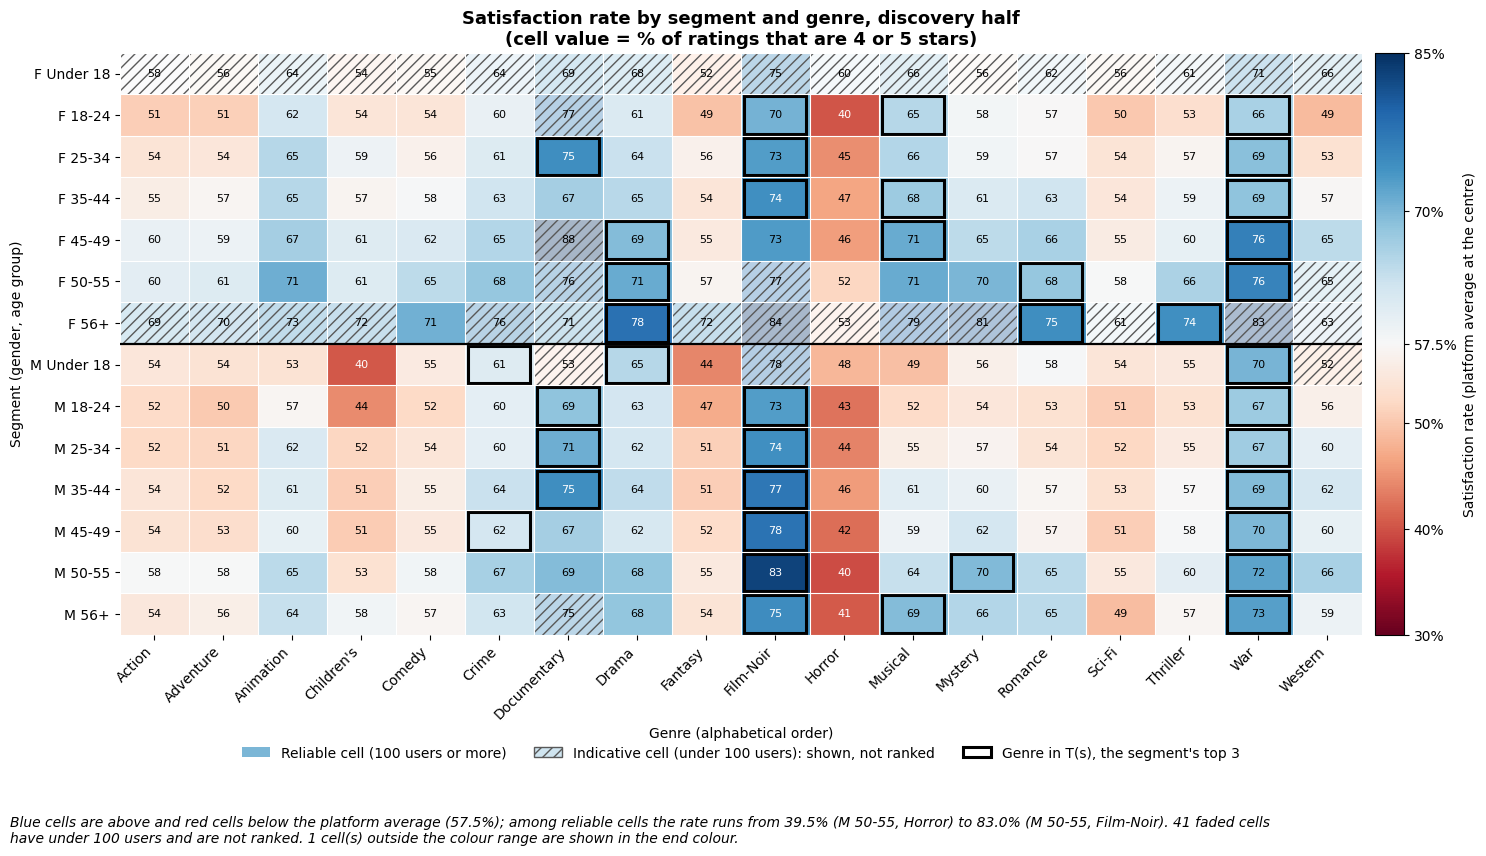

caption: Blue cells are above and red cells below the platform average (57.5%); among reliable cells the rate runs from 39.5% (M 50-55, Horror) to 83.0% (M 50-55, Film-Noir). 41 faded cells have under 100 users and are not ranked. 1 cell(s) outside the colour range are shown in the end colour.


In [35]:
print("STEP B10.1  heatmap of satisfaction rate, discovery half")

disc1 = table1_rates[table1_rates["half"] == "discovery"]

def grid(frame, col):
    wide = frame.pivot(index=["gender", "age_group"], columns="genre", values=col)
    return wide.reindex(index=SEG_INDEX, columns=GENRES)

rate, tier = grid(disc1, "sat_rate"), grid(disc1, "tier")
top3 = grid(table2_lcb, "in_top3")
assert rate.shape == (14, 18) and not rate.isna().any().any(), "heatmap needs 14 x 18 cells without gaps"

cmap = plt.get_cmap(HEAT_CMAP)
norm = TwoSlopeNorm(vmin=HEAT_MIN, vcenter=HEAT_CENTER, vmax=HEAT_MAX)

fig, ax = plt.subplots(figsize=(15, 8.6))
for i in range(14):
    for j in range(18):
        v, reliable = float(rate.iloc[i, j]), tier.iloc[i, j] == "reliable"
        rgba = list(cmap(norm(v)))
        if not reliable:
            rgba[3] = 0.35
        ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, facecolor=rgba, linewidth=0,
                               edgecolor=None if reliable else "0.35", hatch=None if reliable else "///"))
        lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        ax.text(j, i, f"{v * 100:.0f}", ha="center", va="center", fontsize=8,
                color="white" if (reliable and lum < 0.5) else "black")
        if top3.iloc[i, j] is True or top3.iloc[i, j] == True:
            ax.add_patch(Rectangle((j - .45, i - .45), .9, .9, fill=False, edgecolor="black", linewidth=2.2))
ax.hlines(np.arange(-.5, 14), -.5, 17.5, color="white", linewidth=.8)
ax.vlines(np.arange(-.5, 18), -.5, 13.5, color="white", linewidth=.8)
ax.axhline(6.5, color="black", linewidth=1.6)
ax.set_xlim(-.5, 17.5); ax.set_ylim(13.5, -.5)
ax.set_xticks(range(18)); ax.set_xticklabels(GENRES, rotation=45, ha="right")
ax.set_yticks(range(14)); ax.set_yticklabels([SEG_LABEL[s] for s in SEGMENTS])
ax.set_xlabel("Genre (alphabetical order)")
ax.set_ylabel("Segment (gender, age group)")
ax.set_title("Satisfaction rate by segment and genre, discovery half\n(cell value = % of ratings that are 4 or 5 stars)")
for sp in ax.spines.values():
    sp.set_visible(False)

cbar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.025, pad=0.01,
                    ticks=[HEAT_MIN, .40, .50, HEAT_CENTER, .70, HEAT_MAX])
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 100:.1f}%" if abs(v - HEAT_CENTER) < 1e-9 else f"{v * 100:.0f}%"))
cbar.set_label("Satisfaction rate (platform average at the centre)")

handles = [Patch(facecolor=cmap(norm(.70)), label="Reliable cell (100 users or more)"),
           Patch(facecolor=(*cmap(norm(.70))[:3], .35), edgecolor="0.35", hatch="///", label="Indicative cell (under 100 users): shown, not ranked"),
           Patch(fill=False, edgecolor="black", linewidth=2.2, label="Genre in T(s), the segment's top 3")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)

rel = disc1[disc1["tier"] == "reliable"]
hi, lo = rel.loc[rel["sat_rate"].idxmax()], rel.loc[rel["sat_rate"].idxmin()]
n_ind = int((tier == "indicative").sum().sum())
n_clip = int(((rate < HEAT_MIN) | (rate > HEAT_MAX)).sum().sum())
caption = (f"Blue cells are above and red cells below the platform average ({HEAT_CENTER:.1%}); among reliable cells the rate runs from "
           f"{lo['sat_rate']:.1%} ({lo['gender']} {lo['age_group']}, {lo['genre']}) to {hi['sat_rate']:.1%} ({hi['gender']} {hi['age_group']}, {hi['genre']}). "
           f"{n_ind} faded cells have under 100 users and are not ranked."
           + (f" {n_clip} cell(s) outside the colour range are shown in the end colour." if n_clip else ""))
finish(fig, caption, "B10_1_heatmap", bottom=0.07)

### Step B10.2: D(s) by Segment with 95% CI
Validation half (Steps B8 and B9). Each tested segment is one dot: D(s) = mean satisfaction rate of its own top 3 minus that of the common top 3 (B), with the unadjusted 95% bootstrap CI. **Colour shows the conclusion after Holm correction**, not whether the CI contains 0. Segments that were not tested have no dot; the reason is written on their row.

STEP B10.2  D(s) with CI by segment, validation half


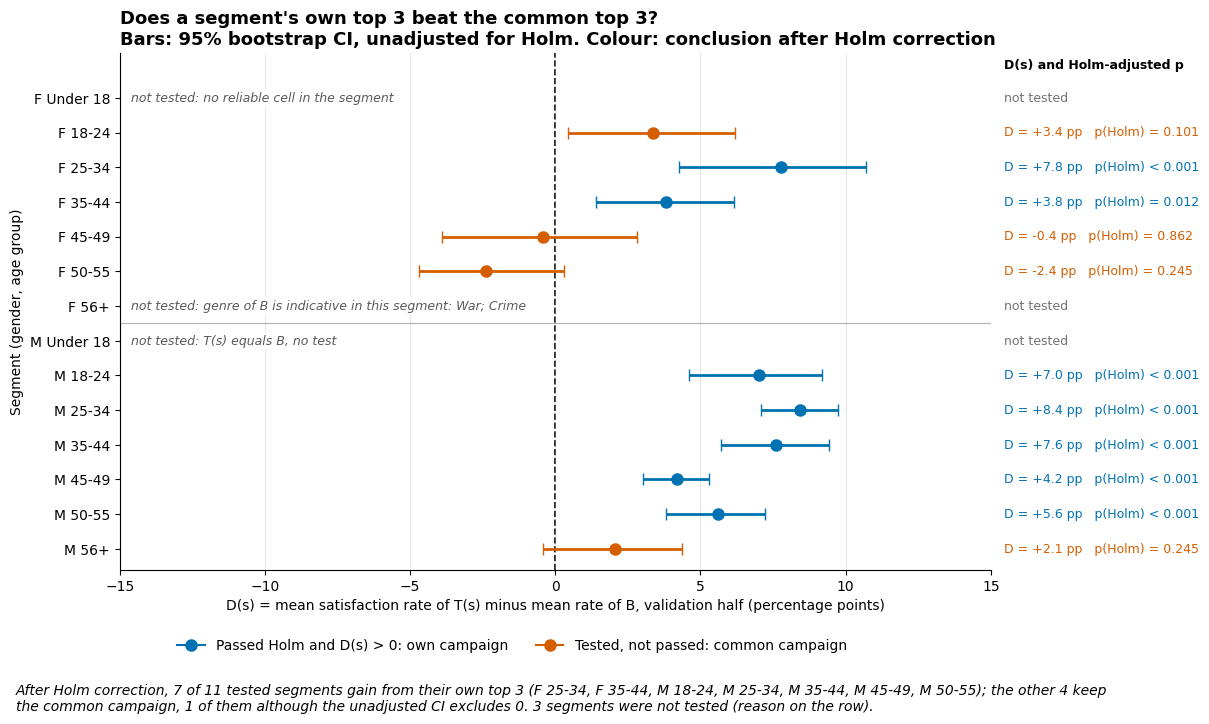

caption: After Holm correction, 7 of 11 tested segments gain from their own top 3 (F 25-34, F 35-44, M 18-24, M 25-34, M 35-44, M 45-49, M 50-55); the other 4 keep the common campaign, 1 of them although the unadjusted CI excludes 0. 3 segments were not tested (reason on the row).


In [36]:
print("STEP B10.2  D(s) with CI by segment, validation half")

seg_order = pd.DataFrame(SEGMENTS, columns=["gender", "age_group"])
res = seg_order.merge(table3_results, on=["gender", "age_group"], how="left", validate="1:1")
assert len(res) == 14 and res["category"].notna().all(), "table3_results must have one row per segment"
tested = res["category"].isin(["passed", "not_passed"])
m = int(tested.sum())
assert m == int(table3_results["m"].iloc[0]), "m in table3_results differs from the number of tested rows"

pp = lambda x: x * 100
lim = max(D_HALF_RANGE_PP, 5 * ceil(max(abs(pp(res.loc[tested, "ci_low"])).max(), abs(pp(res.loc[tested, "ci_high"])).max()) / 5)) if m else D_HALF_RANGE_PP

fig, ax = plt.subplots(figsize=(13, 7.6))
ax.axvline(0, color="black", linestyle="--", linewidth=1.2, zorder=1)
for k, row in res.iterrows():
    if tested[k]:
        col = COLORS[row["category"]]
        ax.errorbar(pp(row["d"]), k, xerr=[[pp(row["d"] - row["ci_low"])], [pp(row["ci_high"] - row["d"])]],
                    fmt="o", color=col, ecolor=col, elinewidth=2, capsize=4, markersize=8, zorder=3)
        label = f"D = {pp(row['d']):+.1f} pp   p(Holm) {fmt_p(row['p_holm'])}"
        ax.annotate(label, xy=(1.015, k), xycoords=("axes fraction", "data"), va="center", fontsize=9, color=col)
    else:
        why = row["reason"] if str(row["reason"]).strip() else row["category"].replace("_", " ")
        ax.text(-lim + 0.4, k, f"not tested: {why}", va="center", ha="left", fontsize=9, style="italic", color="0.35",
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=2)
        ax.annotate("not tested", xy=(1.015, k), xycoords=("axes fraction", "data"), va="center", fontsize=9, color="0.45")
ax.annotate("D(s) and Holm-adjusted p", xy=(1.015, -0.95), xycoords=("axes fraction", "data"), va="center", fontsize=9, fontweight="bold")
ax.axhline(6.5, color="0.7", linewidth=.8)
ax.set_xlim(-lim, lim); ax.set_ylim(13.6, -1.3)
ax.set_yticks(range(14)); ax.set_yticklabels([SEG_LABEL[s] for s in SEGMENTS])
ax.set_xlabel("D(s) = mean satisfaction rate of T(s) minus mean rate of B, validation half (percentage points)")
ax.set_ylabel("Segment (gender, age group)")
ax.grid(axis="x", alpha=.3)
ax.set_title("Does a segment's own top 3 beat the common top 3?\nBars: 95% bootstrap CI, unadjusted for Holm. Colour: conclusion after Holm correction", loc="left")
ax.legend(handles=[Line2D([], [], marker="o", color=COLORS["passed"], linestyle="-", markersize=8, label="Passed Holm and D(s) > 0: own campaign"),
                   Line2D([], [], marker="o", color=COLORS["not_passed"], linestyle="-", markersize=8, label="Tested, not passed: common campaign")],
          loc="upper center", bbox_to_anchor=(0.45, -0.11), ncol=2, frameon=False)
fig.subplots_adjust(left=0.09, right=0.76, top=0.88, bottom=0.2)

n_pass = int((res["category"] == "passed").sum())
names = ", ".join(res.loc[res["category"] == "passed", "segment"])
n_ci_only = int(((res["category"] == "not_passed") & (res["ci_low"] > 0)).sum())
n_untested = 14 - m
caption = (f"After Holm correction, {n_pass} of {m} tested segments gain from their own top 3" + (f" ({names})" if n_pass else "") +
           f"; the other {m - n_pass} keep the common campaign" +
           (f", {n_ci_only} of them although the unadjusted CI excludes 0" if n_ci_only else "") +
           f". {n_untested} segments were not tested (reason on the row).")
finish(fig, caption, "B10_2_difference_by_segment", tight=False)

### Step B10.3: T(s) against B, Dumbbell
Validation half (Step B8), tested segments only. For each segment the grey square is the mean satisfaction rate of the common top 3 (B) and the circle is the mean rate of the segment's own top 3 T(s); the line between them is D(s). The x-axis starts at 40% (stated on the axis): the chart encodes the position of the dots, not bar lengths, so no bar is cut. Circle colours are the same as in Step B10.2.

STEP B10.3  T(s) against B, dumbbell, validation half


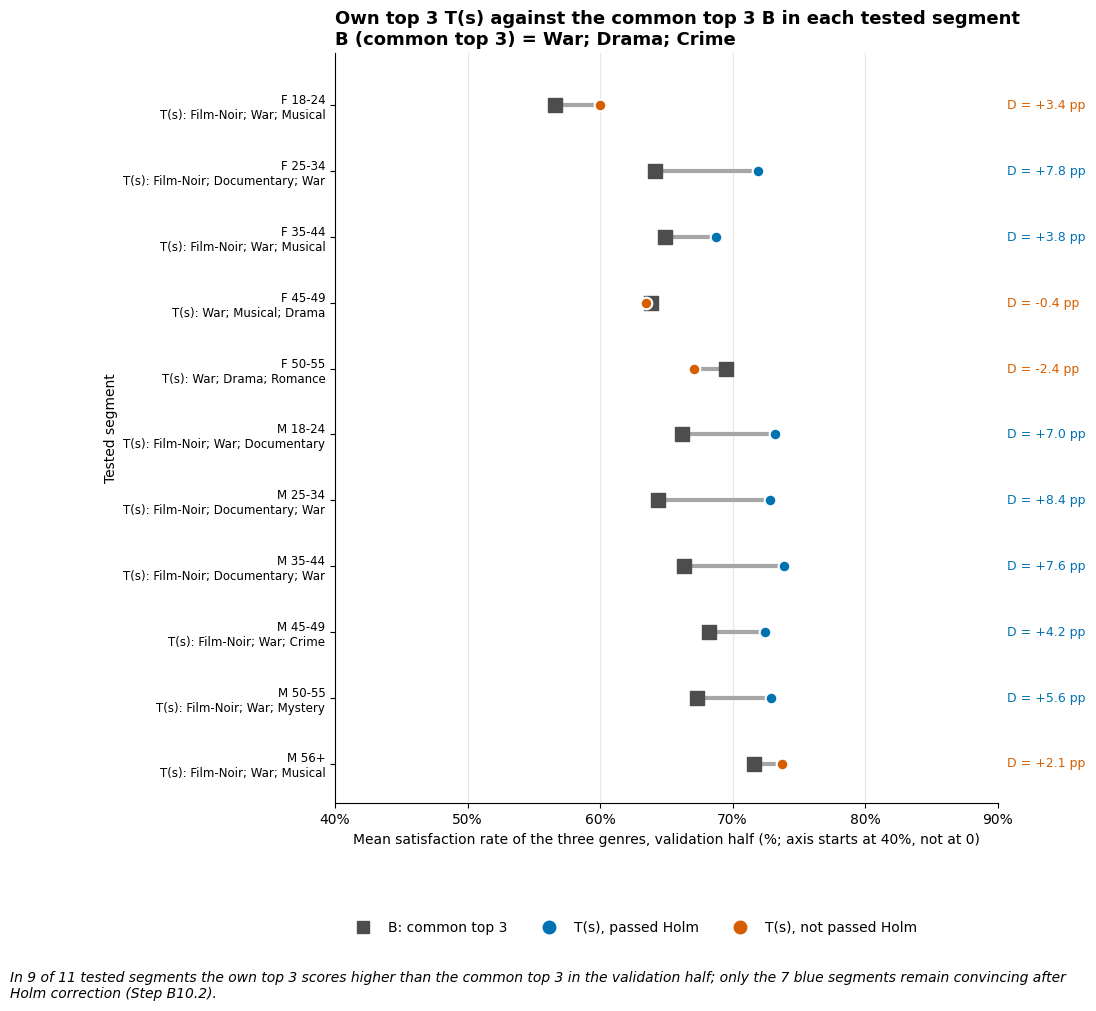

caption: In 9 of 11 tested segments the own top 3 scores higher than the common top 3 in the validation half; only the 7 blue segments remain convincing after Holm correction (Step B10.2).


In [37]:
print("STEP B10.3  T(s) against B, dumbbell, validation half")

td = res[tested].reset_index(drop=True)
if td.empty:
    print("no tested segment: nothing to draw")
else:
    xlim3 = widen(DUMBBELL_XLIM, np.r_[td["mean_r_b"], td["mean_r_ts"]], 0.05)
    fig, ax = plt.subplots(figsize=(12.5, 1.0 + 0.62 * len(td) + 2.6))
    for k, row in td.iterrows():
        col = COLORS[row["category"]]
        ax.plot([row["mean_r_b"], row["mean_r_ts"]], [k, k], color="0.65", linewidth=3, zorder=1)
        ax.scatter(row["mean_r_b"], k, marker="s", s=100, color=COLORS["B"], zorder=2)
        ax.scatter(row["mean_r_ts"], k, marker="o", s=70, color=col, edgecolors="white", linewidths=1.5, zorder=3)
        ax.annotate(f"D = {pp(row['d']):+.1f} pp", xy=(1.015, k), xycoords=("axes fraction", "data"), va="center", fontsize=9, color=col)
    ax.set_yticks(range(len(td)))
    ax.set_yticklabels([f"{r['segment']}\nT(s): {r['t_s']}" for _, r in td.iterrows()], fontsize=8.5)
    ax.set_ylim(len(td) - .4, -.8)
    ax.set_xlim(*xlim3)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlabel(f"Mean satisfaction rate of the three genres, validation half (%; axis starts at {xlim3[0]:.0%}, not at 0)")
    ax.set_ylabel("Tested segment")
    ax.grid(axis="x", alpha=.3)
    b_txt = f"\nB (common top 3) = {'; '.join(B_GENRES)}" if B_GENRES else ""
    ax.set_title("Own top 3 T(s) against the common top 3 B in each tested segment" + b_txt, loc="left")
    ax.legend(handles=[Line2D([], [], marker="s", color=COLORS["B"], linestyle="", markersize=8, label="B: common top 3"),
                       Line2D([], [], marker="o", color=COLORS["passed"], linestyle="", markersize=9, label="T(s), passed Holm"),
                       Line2D([], [], marker="o", color=COLORS["not_passed"], linestyle="", markersize=9, label="T(s), not passed Holm")],
              loc="upper center", bbox_to_anchor=(0.45, -0.14), ncol=3, frameon=False)
    fig.subplots_adjust(left=0.27, right=0.80, top=0.92, bottom=0.2)
    n_higher = int((td["d"] > 0).sum())
    caption = (f"In {n_higher} of {len(td)} tested segments the own top 3 scores higher than the common top 3 in the validation half; "
               f"only the {n_pass} blue segments remain convincing after Holm correction (Step B10.2).")
    finish(fig, caption, "B10_3_dumbbell_ts_vs_b", tight=False)

### Step B10.4: Exploratory, Reach against Satisfaction Rate
**Exploratory. Not used for any recommendation.** Discovery half. Each dot is one of the 252 cells: reach (share of the segment's users who rated that genre) on the x-axis and satisfaction rate on the y-axis. It shows whether the genres that most users watch are also the ones they like, which is a description of the data, not a test.

STEP B10.4  exploratory: reach against satisfaction rate, discovery half
cells: 252, reliable: 211
Spearman rho, all cells      : -0.230
Spearman rho, reliable cells : -0.149


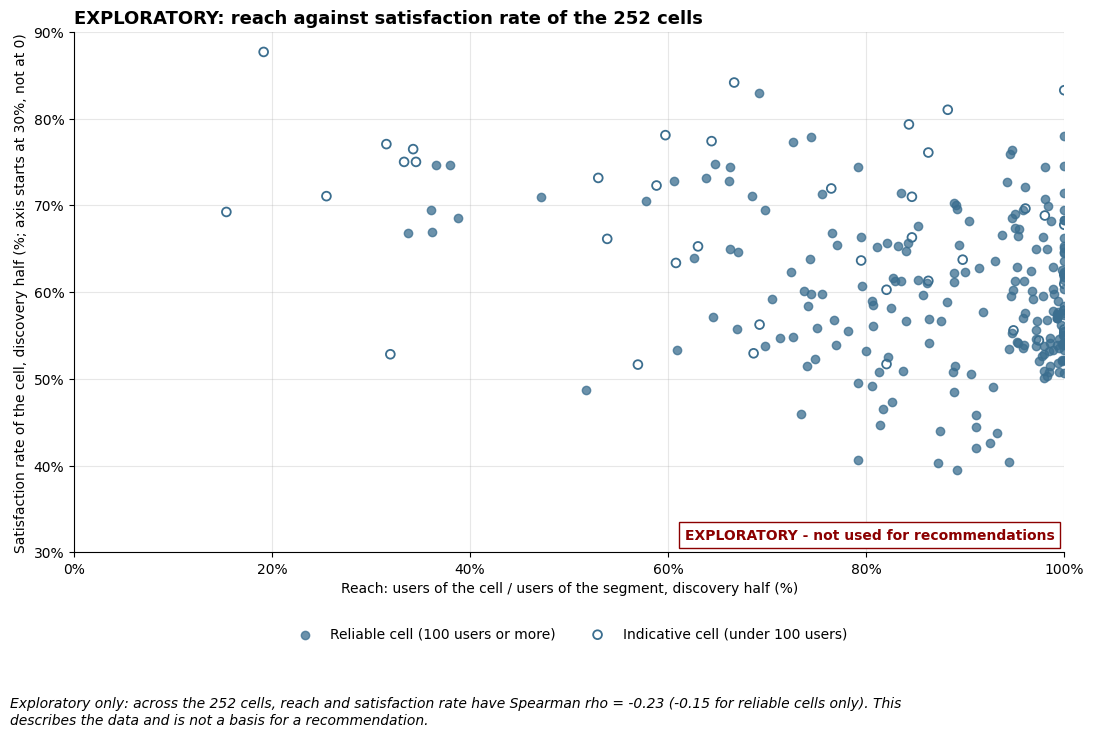

caption: Exploratory only: across the 252 cells, reach and satisfaction rate have Spearman rho = -0.23 (-0.15 for reliable cells only). This describes the data and is not a basis for a recommendation.


In [38]:
print("STEP B10.4  exploratory: reach against satisfaction rate, discovery half")

c4 = table1_rates[table1_rates["half"] == "discovery"].copy()
assert len(c4) == 252, "expected 252 cells in the discovery half"
ylim4 = widen(SCATTER_YLIM, c4["sat_rate"], 0.05)
rho_all = c4["reach"].rank().corr(c4["sat_rate"].rank())
rel4 = c4[c4["tier"] == "reliable"]
rho_rel = rel4["reach"].rank().corr(rel4["sat_rate"].rank())
print(f"cells: {len(c4)}, reliable: {len(rel4)}")
print(f"Spearman rho, all cells      : {rho_all:.3f}")
print(f"Spearman rho, reliable cells : {rho_rel:.3f}")

fig, ax = plt.subplots(figsize=(11, 7.4))
ind = c4[c4["tier"] == "indicative"]
ax.scatter(rel4["reach"], rel4["sat_rate"], s=36, color="#3B6E8F", alpha=.75, label="Reliable cell (100 users or more)", zorder=3)
ax.scatter(ind["reach"], ind["sat_rate"], s=40, facecolors="none", edgecolors="#3B6E8F", linewidths=1.3,
           label="Indicative cell (under 100 users)", zorder=3)
ax.set_xlim(*SCATTER_XLIM); ax.set_ylim(*ylim4)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Reach: users of the cell / users of the segment, discovery half (%)")
ax.set_ylabel(f"Satisfaction rate of the cell, discovery half (%; axis starts at {ylim4[0]:.0%}, not at 0)")
ax.grid(alpha=.3)
ax.set_title("EXPLORATORY: reach against satisfaction rate of the 252 cells", loc="left")
ax.text(0.99, 0.02, "EXPLORATORY - not used for recommendations", transform=ax.transAxes, ha="right", va="bottom",
        fontsize=10, fontweight="bold", color="#8B0000", bbox=dict(facecolor="white", edgecolor="#8B0000", pad=4))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
caption = (f"Exploratory only: across the {len(c4)} cells, reach and satisfaction rate have Spearman rho = {rho_all:.2f} "
           f"({rho_rel:.2f} for reliable cells only). This describes the data and is not a basis for a recommendation.")
finish(fig, caption, "B10_4_exploratory_reach_vs_rate")

## Notes for the merge and for the presentation
**Inputs.** The charts read the tables of Steps B3 to B9 as they are; no number is recomputed here. All numbers in the captions are printed by the same Step. The schema check stops the notebook if a column or label differs from `D3_columns_HoangQuan_v2`; if the column file changes again, only `SCHEMA` and the column names used in Steps B10.1 to B10.4 need updating.

**Self-check against the brief.**
- Scales were frozen before any real number existed (design table at the top); the only changes made after seeing the data are the widening rules written there (B10.1 colour range unchanged; B10.2 range widened because a CI end exceeded 10 pp; see the printed values).
- No bar chart is used. Axes that do not start at 0 (B10.3, B10.4) say so in the axis label and encode position, not length.
- The "measure may differ" note of the D2 charts is gone: D(s) is computed on ratings, like the satisfaction rate.
- Colour in B10.2 follows the Holm conclusion. Segments not tested show their reason. CI is labelled "unadjusted".
- Every number in a caption is printed from the data in the same Step; no figure is typed by hand except the frozen scales and the platform average used as colour centre.

**Why these chart types (questions for the presentation).**
- B10.1 heatmap: 252 cells need a matrix, and position plus colour lets the team find strong and weak genres per segment in seconds; the hatch keeps thin cells visible but visibly less certain.
- B10.2 dot with interval: the question is "is the difference above 0?", so the zero line and the CI are the whole message; colour follows the Holm decision because that is the rule agreed in D1.
- B10.3 dumbbell: shows the two scores being compared and the gap between them on one common scale, without drawing bars from a cut-off baseline.
- B10.4 scatter: reach and rate are two continuous measures per cell; a scatter shows the relationship (or its absence) and is labelled exploratory.

**What a reader should take from chart 2.** Whether a segment's own campaign is supported is decided by the colour (the Holm result), not by how large D(s) looks or by whether the unadjusted CI touches 0. A blue dot means "use the segment's own top 3"; an orange dot or an untested row means "keep the common campaign".

## Data manipulation operations (index)
| Operation | Where | What it does |
|-----------|-------|--------------|
| Merging two tables | Step 3 | left joins ratings, users and movies with validate="m:1" and asserts the row count |
| Creating a derived column | Steps 4, 7, 8 | year and age_group (Step 4), tier (Step 7), satisfied flag (Step 8) |
| Filtering | Step 7b | keeps the reliable cells (≥ 100 distinct users) used for ranking, counts printed before and after |
| Grouping and aggregation | Steps 6, 8 | users, ratings and satisfaction rate per gender x age_group x genre cell |

Step 5 (explode genres into one row per rating-genre pair) prepares the data for Steps 6 and 8 and is not counted as a fifth operation.

### Things that do NOT change the row count
- Steps 5 and 6 never modify `df`; they build `exploded` and the cell table from it. Cell sizes are counted in distinct users, and a user who rated several genres is counted in several cells of the same segment, so the cell sizes inside one segment do not add up to that segment's number of users.

## Inputs for the other roles
Environment and column lists printed from this notebook, so teammates take them from here instead of typing them by hand.

In [39]:
print("HANDOFF  environment and column lists")

import platform
from datetime import date
from importlib.metadata import version

print(f"run date: {date.today().isoformat()}")
print(f"python  : {platform.python_version()}")
for pkg in ("numpy", "pandas", "matplotlib", "statsmodels"):
    print(f"{pkg:<8}: {version(pkg)}")
print(f"seed    : {SEED}")

print("\nworking table df, columns")
for col, dtype in df.dtypes.items():
    print(f"  {col:<12} {dtype}")

print("\nexploded table, columns")
for col, dtype in exploded.dtypes.items():
    print(f"  {col:<12} {dtype}")

print("\ncell table rates, columns")
for col, dtype in rates.dtypes.items():
    print(f"  {col:<12} {dtype}")

HANDOFF  environment and column lists
run date: 2026-11-20
python  : 3.13.18
numpy   : 2.4.6
pandas  : 2.2.3
matplotlib: 3.10.0
statsmodels: 0.15.0
seed    : 42

working table df, columns
  user_id      int64
  movie_id     int64
  rating       int64
  timestamp    int64
  gender       object
  age          int64
  title        object
  genres       object
  year         Int64
  age_group    object
  half         object

exploded table, columns
  user_id      int64
  movie_id     int64
  rating       int64
  timestamp    int64
  gender       object
  age          int64
  title        object
  genres       object
  year         Int64
  age_group    object
  genre        object
  n_genres     int64
  satisfied    bool
  half         object

cell table rates, columns
  gender       object
  age_group    object
  genre        object
  n_ratings    int64
  n_users      int64
  n_satisfied  int64
  sat_rate     float64
  tier         object


## Cleaning log

Every figure below is printed by the Step named in the "Step" column. Rows C1 to C17 come from the D2 run of 2026-10-20 and every rerun must print the same figures; C18 and C19 were added in D3. Row counts refer to the 1,000,209-row ratings table unless stated otherwise.

| ID | Step | Check | Finding | Decision | Reason | Before → After |
|----|------|-------|---------|----------|--------|----------------|
| C1 | 2 | Missing values in `ratings`, `users`, `movies` | 0 missing in every column of all three tables | Keep as is | Nothing to impute or drop | 1,000,209 / 6,040 / 3,883 rows → unchanged |
| C2 | 2 | Primary key uniqueness | `users.user_id` and `movies.movie_id` are unique | Keep as is | Joins are many-to-one, so no row can multiply | unchanged |
| C3 | 2 | Orphan foreign keys in `ratings` | 0 rows with an unknown `user_id`, 0 with an unknown `movie_id` | Keep as is | Every rating can be joined | unchanged |
| C4 | 2c | Duplicate ratings | 0 repeated (`user_id`, `movie_id`) pairs, 0 fully identical rows | Nothing removed | No duplicates exist | 1,000,209 → 1,000,209 |
| C5 | 2c | Valid value ranges | `rating` ∈ {1,2,3,4,5}; `gender` ∈ {F, M}; ratings dated 2000-04-25 to 2003-02-28 | Keep as is | All values are inside the documented domain | unchanged |
| C6 | 2c | Films nobody rated | 3,883 films in `movies.dat`, 3,706 with at least 1 rating, 177 never rated | Left joins start from `ratings`, so the 177 films do not appear in the working table | A film with no rating carries no preference signal | 3,883 → 3,706 films in `df` |
| C7 | 3 | Merge `ratings` + `users` + `movies` | Left joins with `validate="m:1"`; row count asserted equal to `ratings` | Merged into one working table | One row per rating with user and film attributes | 1,000,209 → 1,000,209 rows; 4 → 10 columns |
| C8 | 3b | Personal columns | `zip` (3,439 distinct) could single out a person when combined with gender and age band; `occupation` is not used in the analysis | Dropped `zip` and `occupation` | Privacy and relevance, as committed in D1 | 10 → 8 columns |
| C9 | 4 / 4b | Release year parsed from `title` | 0 unparsed titles; years 1919–2000; 81 distinct years in rated films and in `movies.dat`; the only year without a film inside the span is 1924 | Added `year` | Needed for any release-period cut | 8 → 9 columns |
| C10 | 4 | Age code to label | 0 unmapped codes; 7 groups: Under 18 (27,211), 18-24 (183,536), 25-34 (395,556), 35-44 (199,003), 45-49 (83,633), 50-55 (72,490), 56+ (38,780); counts sum to 1,000,209 | Added `age_group` | Readable and ordered labels for the age groups | 9 → 10 columns |
| C11 | 5 | Multi-genre films | A rating row carries 1–6 genre labels (mean 2.1014); 301 distinct genre strings; 18 distinct genres | Exploded to one row per rating-genre pair, in a separate table `exploded`; `df` is untouched | The unit of analysis is the genre | 1,000,209 → 2,101,815 rows (×2.1014) |
| C12 | 6 / 7 | Sparsity of the 252 cells (2 genders × 7 age groups × 18 genres) | Distinct users per cell: min 11, median 270.5, max 1,538; 41 cells under 100 users | Tier frozen before any satisfaction rate was computed: reliable ≥ 100 distinct users, indicative < 100 | Threshold fixed in D1 Section 5, so it cannot be tuned to the outcome | 252 cells → 211 reliable / 41 indicative |
| C13 | 7b | Cells used for ranking | 211 reliable cells; the 41 indicative cells are listed in Step 6 | Kept reliable cells for ranking; indicative cells set aside and reported as indicative only, not pooled | D1 Section 5 allows “pooled or reported as indicative only”; the second option needs no extra rule | 252 → 211 cells |
| C14 | 8 | Satisfaction rate per cell | satisfied = rating ≥ 4; all rates in [0, 1] | Rate reported without a confidence interval | Ratings from one user are not independent; user-level intervals are computed in D3 | 252 cells with a rate |
| C15 | 9 | Profile of the final working table `df` | 1,000,209 rows × 10 columns, 0 missing, 81 distinct years, 7 age groups | Final | Table handed to the analysts | 10 columns |
| C16 | 2c | User activity | Fewest ratings by one user: 20 | No activity filter | GroupLens already kept only users with at least 20 ratings; heavy raters are handled by counting cell size in distinct users | unchanged |
| C17 | 2d | Additional checks (Data Analyst A, Que) | Row counts match the README (1,000,209 ratings, 6,040 users); 0 ratings dated before the film's release year; 774,028 ratings (77.4%) share the same second with another rating by the same user, largest burst 30 | Keep as is | Timestamp records when a rating was entered, often in bulk, not when the film was watched, so no conclusion in this project relies on rating time | unchanged |
| C18 | B1 | Discovery and validation split | Users of each of the 14 segments split 50/50 with seed 42; discovery 3,018 users (504,116 ratings), validation 3,022 users (496,093 ratings); halves differ by at most one user per segment | Each user is assigned to exactly one half; the extra user of an odd-sized segment goes to validation | Genres are chosen on one half and tested on the other, so selection noise is not tested on the same data; the split is by user because ratings from one user are not independent | 6,040 users → 3,018 discovery / 3,022 validation |
| C19 | 1 | Data source | Colab could not verify the GroupLens certificate on 2026-10-24 (SSL CERTIFICATE_VERIFY_FAILED); in this run Step 1 printed "source : https://files.grouplens.org/datasets/movielens/ml-1m.zip (download, attempt 1)" | Download with certifi certificates, up to 3 attempts; if all fail, read `data/ml-1m.zip` (a local copy of the same official file, never committed) | Certificate verification is never turned off; the data stays the official GroupLens file | unchanged |